In [ ]:
# ===== CELL 1: setup and study area (Tharparkar) =====
GEE_PROJECT = 'YOUR-GEE-PROJECT-ID'
import ee, os, json, math, time, requests, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)
os.makedirs('outputs', exist_ok=True)

START_YEAR, END_YEAR = 2001, 2024

gaul = (ee.FeatureCollection('FAO/GAUL/2015/level2')
        .filter(ee.Filter.eq('ADM0_NAME', 'Pakistan'))
        .filter(ee.Filter.stringContains('ADM2_NAME', 'Thar')))
if gaul.size().getInfo() >= 1:
    districts, NAME_PROP = gaul, 'ADM2_NAME'
else:
    districts = (ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM2')
                 .filter(ee.Filter.eq('shapeGroup', 'PAK'))
                 .filter(ee.Filter.stringContains('shapeName', 'Thar')))
    NAME_PROP = 'shapeName'
roi = districts.geometry()
print('Found:', districts.aggregate_array(NAME_PROP).getInfo())
print('Area km2:', round(roi.area(1).divide(1e6).getInfo()))

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


Found: ['Tharparkar District']
Area km2: 19622


2001 done
2002 done
2003 done
2004 done
2005 done
2006 done
2007 done
2008 done
2009 done
2010 done
2011 done
2012 done
2013 done
2014 done
2015 done
2016 done
2017 done
2018 done
2019 done
2020 done
2021 done
2022 done
2023 done
2024 done


,TCI,VCI,VHI,month,year
0,4.386612,21.971200,13.155899,1,2001
1,26.609635,21.302223,23.971798,2,2001
2,13.627737,16.272442,14.956770,3,2001
3,47.718307,19.113293,33.424366,4,2001
4,43.268515,10.879465,27.089149,5,2001
5,38.574785,29.248183,33.631014,6,2001
6,39.173919,85.510629,61.761821,7,2001
7,73.079385,54.937641,64.100094,8,2001
8,20.332073,31.973261,26.153124,9,2001
9,27.981752,33.353496,30.669851,10,2001


288 months (should be 288)


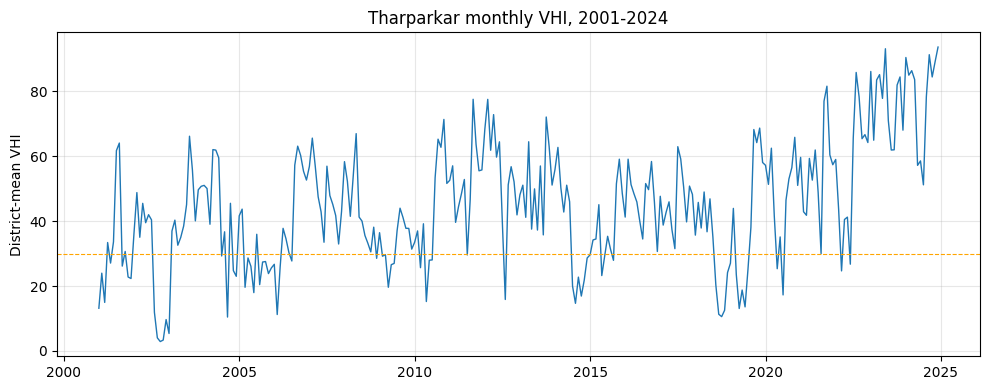

In [ ]:
# ===== CELL 2: monthly VCI/TCI/VHI (MODIS) and district-mean time series =====
ndvi_c = (ee.ImageCollection('MODIS/061/MOD13A2')
          .filterDate(f'{START_YEAR}-01-01', f'{END_YEAR + 1}-01-01')
          .map(lambda i: i.select('NDVI').multiply(0.0001)
               .updateMask(i.select('SummaryQA').lte(1)).rename('NDVI')
               .copyProperties(i, ['system:time_start'])))
lst_c = (ee.ImageCollection('MODIS/061/MOD11A2')
         .filterDate(f'{START_YEAR}-01-01', f'{END_YEAR + 1}-01-01')
         .map(lambda i: i.select('LST_Day_1km').multiply(0.02)
              .updateMask(i.select('QC_Day').bitwiseAnd(3).lte(1)).rename('LST')
              .copyProperties(i, ['system:time_start'])))

years = ee.List.sequence(START_YEAR, END_YEAR)
months = ee.List.sequence(1, 12)

def make_month(y, m):
    y = ee.Number(y); m = ee.Number(m)
    s = ee.Date.fromYMD(y, m, 1); e = s.advance(1, 'month')
    img = (ndvi_c.filterDate(s, e).mean().rename('NDVI')
           .addBands(lst_c.filterDate(s, e).mean().rename('LST')))
    return img.set({'year': y, 'month': m, 'system:time_start': s.millis()})

monthly = ee.ImageCollection.fromImages(
    years.map(lambda y: months.map(lambda m: make_month(y, m))).flatten())

def clim(m):
    sub = monthly.filter(ee.Filter.eq('month', m))
    return ee.Image.cat([
        sub.select('NDVI').min().rename('NDVI_min'), sub.select('NDVI').max().rename('NDVI_max'),
        sub.select('LST').min().rename('LST_min'), sub.select('LST').max().rename('LST_max')]).set('month', m)
climc = ee.ImageCollection.fromImages(months.map(clim))

def add_vhi(img):
    c = ee.Image(climc.filter(ee.Filter.eq('month', img.get('month'))).first())
    vci = (img.select('NDVI').subtract(c.select('NDVI_min'))
           .divide(c.select('NDVI_max').subtract(c.select('NDVI_min'))).multiply(100).rename('VCI'))
    tci = (c.select('LST_max').subtract(img.select('LST'))
           .divide(c.select('LST_max').subtract(c.select('LST_min'))).multiply(100).rename('TCI'))
    vhi = vci.multiply(0.5).add(tci.multiply(0.5)).rename('VHI')
    return vci.addBands([tci, vhi]).copyProperties(img, ['year', 'month', 'system:time_start'])
vhi_c = monthly.map(add_vhi)

def stat(img):
    d = img.reduceRegion(ee.Reducer.mean(), roi, 1000, maxPixels=1e9, tileScale=4)
    return ee.Feature(None, d).set({'year': img.get('year'), 'month': img.get('month')})

rows = []
for y in range(START_YEAR, END_YEAR + 1):
    for attempt in range(3):
        try:
            feats = vhi_c.filter(ee.Filter.eq('year', y)).map(stat).getInfo()['features']
            rows += [f['properties'] for f in feats]
            print(y, 'done'); break
        except Exception as e:
            print(y, 'retry:', str(e)[:80]); time.sleep(5)

ts = pd.DataFrame(rows).sort_values(['year', 'month']).reset_index(drop=True)
ts.to_csv('outputs/vhi_monthly_timeseries.csv', index=False)
display(ts.head(12)); print(len(ts), 'months (should be 288)')

plt.figure(figsize=(10, 4))
x = ts['year'] + (ts['month'] - 1) / 12
plt.plot(x, ts['VHI'], lw=1); plt.axhline(30, color='orange', ls='--', lw=.8)
plt.ylabel('District-mean VHI'); plt.title('Tharparkar monthly VHI, 2001-2024'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/fig_vhi_timeseries.png', dpi=200); plt.show()

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


2001 rain done
2002 rain done
2003 rain done
2004 rain done
2005 rain done
2006 rain done
2007 rain done
2008 rain done
2009 rain done
2010 rain done
2011 rain done
2012 rain done
2013 rain done
2014 rain done
2015 rain done
2016 rain done
2017 rain done
2018 rain done
2019 rain done
2020 rain done
2021 rain done
2022 rain done
2023 rain done
2024 rain done


,year,rain_JulOct,SPI_JulOct,VCI_JulOct,TCI_JulOct,VHI_JulOct,TCI_VHI_reliable
0,2001,169.44,-0.69,51.44,40.14,45.67,True
1,2002,23.31,-3.04,6.65,23.00,14.81,True
2,2003,402.22,0.83,53.89,49.94,51.79,True
3,2004,104.28,-1.38,14.35,46.68,30.49,True
4,2005,167.84,-0.70,20.03,35.76,27.84,True
5,2006,461.60,1.12,41.41,63.23,52.12,True
6,2007,218.45,-0.28,49.78,46.18,47.95,True
7,2008,182.73,-0.57,28.27,41.44,34.84,True
8,2009,292.30,0.22,43.47,36.11,40.04,True
9,2010,440.92,1.02,56.07,49.33,52.39,True


2001-2024 | correlation with Jul-Oct SPI: {'VCI': np.float64(0.74), 'TCI': np.float64(0.63), 'VHI': np.float64(0.73)}
2001-2019 | correlation with Jul-Oct SPI: {'VCI': np.float64(0.77), 'TCI': np.float64(0.71), 'VHI': np.float64(0.81)}
Jul-Oct seasons with SPI <= -1 (dry): [2002, 2004, 2018]


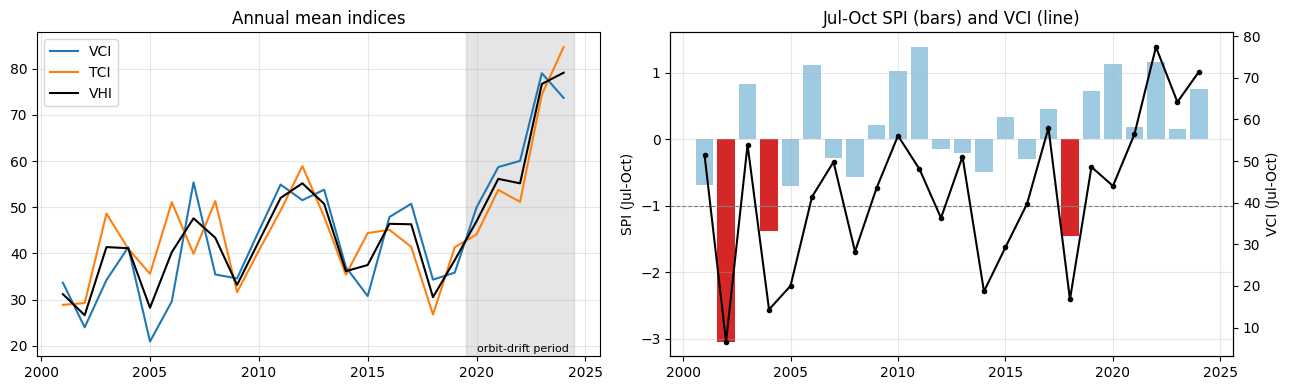

In [ ]:
# ===== CELL 3 (final): yearly summary, CHIRPS rainfall, SPI, drift-aware checks =====
from scipy import stats
DRIFT_FROM = 2020     # Terra/Aqua orbit drift: TCI/VHI from this year on are treated as unreliable

ts['year'] = ts['year'].astype(int); ts['month'] = ts['month'].astype(int)

# --- CHIRPS rainfall (annual and Jul-Oct), district mean ---
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation')
def yearly_rain(y):
    img = ee.Image.cat([
        chirps.filterDate(f'{y}-01-01', f'{y+1}-01-01').sum().rename('rain_annual'),
        chirps.filterDate(f'{y}-07-01', f'{y}-11-01').sum().rename('rain_JulOct')])
    for attempt in range(3):
        try:
            r = img.reduceRegion(ee.Reducer.mean(), roi, 5566, maxPixels=1e9, tileScale=4).getInfo()
            print(y, 'rain done'); return {'year': y, **r}
        except Exception as e:
            print(y, 'retry:', str(e)[:80]); time.sleep(5)
    return {'year': y}
rain = pd.DataFrame([yearly_rain(y) for y in range(START_YEAR, END_YEAR + 1)])

# --- yearly summary (all months and Jul-Oct) ---
ann = ts.groupby('year')[['VCI', 'TCI', 'VHI']].mean().reset_index()
jo = (ts[ts['month'].between(7, 10)].groupby('year')[['VCI', 'TCI', 'VHI']]
      .mean().add_suffix('_JulOct').reset_index())
d = ann.merge(jo, on='year').merge(rain, on='year')

# --- SPI for the Jul-Oct season (gamma fit, 2001-2024 baseline) ---
r = d['rain_JulOct'].values
q = float((r == 0).mean())
shape, loc, scale = stats.gamma.fit(r[r > 0], floc=0)
cdf = q + (1 - q) * stats.gamma.cdf(r, shape, loc=loc, scale=scale)
d['SPI_JulOct'] = stats.norm.ppf(np.clip(cdf, 1e-6, 1 - 1e-6))

# --- drift flag: TCI/VHI kept for the record but marked unreliable from DRIFT_FROM ---
d['TCI_VHI_reliable'] = d['year'] < DRIFT_FROM
d.to_csv('outputs/yearly_summary_with_SPI.csv', index=False)
display(d[['year', 'rain_JulOct', 'SPI_JulOct', 'VCI_JulOct', 'TCI_JulOct', 'VHI_JulOct',
           'TCI_VHI_reliable']].round(2))

# --- checks ---
for lab, sub in [('2001-2024', d), (f'2001-{DRIFT_FROM-1}', d[d['year'] < DRIFT_FROM])]:
    print(lab, '| correlation with Jul-Oct SPI:',
          {k: round(sub[k + '_JulOct'].corr(sub['SPI_JulOct']), 2) for k in ['VCI', 'TCI', 'VHI']})
print('Jul-Oct seasons with SPI <= -1 (dry):', d.loc[d['SPI_JulOct'] <= -1, 'year'].tolist())

# --- figures ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(d['year'], d['VCI'], label='VCI'); ax[0].plot(d['year'], d['TCI'], label='TCI')
ax[0].plot(d['year'], d['VHI'], label='VHI', c='k')
ax[0].axvspan(DRIFT_FROM - 0.5, END_YEAR + 0.5, color='gray', alpha=0.2)
ax[0].text(DRIFT_FROM, ax[0].get_ylim()[0] + 1, 'orbit-drift period', fontsize=8)
ax[0].set_title('Annual mean indices'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar(d['year'], d['SPI_JulOct'], color=np.where(d['SPI_JulOct'] <= -1, '#d62728', '#9ecae1'))
ax[1].axhline(-1, color='gray', ls='--', lw=.8); ax[1].set_ylabel('SPI (Jul-Oct)')
a2 = ax[1].twinx(); a2.plot(d['year'], d['VCI_JulOct'], 'k-o', ms=3); a2.set_ylabel('VCI (Jul-Oct)')
ax[1].set_title('Jul-Oct SPI (bars) and VCI (line)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/fig_diagnostics.png', dpi=200); plt.show()

In [ ]:
# ===== CELL 4 (final): build all map layers in Earth Engine and download them as small GeoTIFFs =====
import zipfile

# the dry seasons shown on the maps: every Jul-Oct season with SPI <= -1 (from Cell 3)
DRY_YEARS = sorted(d.loc[d['SPI_JulOct'] <= -1, 'year'].astype(int).tolist())
print('Dry seasons used for the event maps:', DRY_YEARS)

# rainfall layers (CHIRPS, Jul-Oct total of each year)
def jo_rain(y):
    s = ee.Date.fromYMD(ee.Number(y), 7, 1)
    return (chirps.filterDate(s, s.advance(4, 'month')).sum()
            .rename('r').set('year', ee.Number(y)))
rain_c = ee.ImageCollection.fromImages(ee.List.sequence(START_YEAR, END_YEAR).map(jo_rain))
rmean = rain_c.mean()

water = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').unmask(0).gte(25)

layers = {
    'def_freq': (rain_c.map(lambda i: i.lt(rmean.multiply(0.75))).mean().multiply(100).rename('def_freq'), 5566),
    'rain_mean': (rmean.rename('rain_mean'), 5566),
    'ndvi_mean': (ndvi_c.filter(ee.Filter.calendarRange(7, 10, 'month')).mean()
                  .rename('ndvi_mean').updateMask(water.Not()), 1000),
}
for y in DRY_YEARS:
    layers[f'rainpct_{y}'] = (rain_c.filter(ee.Filter.eq('year', y)).first()
                              .divide(rmean).multiply(100).rename('rp'), 5566)
    layers[f'vci_{y}'] = (vhi_c.filter(ee.Filter.eq('year', y))
                          .filter(ee.Filter.inList('month', [7, 8, 9, 10]))
                          .select('VCI').mean().rename('v').updateMask(water.Not()), 1000)

# download extent
(coords,) = roi.bounds().coordinates().getInfo()
x0, x1 = min(c[0] for c in coords), max(c[0] for c in coords)
y0, y1 = min(c[1] for c in coords), max(c[1] for c in coords)
rect = ee.Geometry.Rectangle([x0, y0, x1, y1])

for name, (img, scale_m) in layers.items():
    img = img.toFloat().clip(roi).unmask(-9999)
    ok = False
    for attempt in range(3):
        try:
            url = img.getDownloadURL({'region': rect, 'scale': scale_m,
                                      'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})
            r = requests.get(url, timeout=900); r.raise_for_status()
            fn = f'outputs/thar_{name}.tif'
            if zipfile.is_zipfile(io.BytesIO(r.content)):
                z = zipfile.ZipFile(io.BytesIO(r.content))
                open(fn, 'wb').write(z.read([n for n in z.namelist() if n.endswith('.tif')][0]))
            else:
                open(fn, 'wb').write(r.content)
            print(name, 'downloaded'); ok = True; break
        except Exception as e:
            print(name, 'retry:', str(e)[:200]); time.sleep(5)
    if not ok:
        print(name, 'FAILED - send me the message above')

Dry seasons used for the event maps: [2002, 2004, 2018]


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


def_freq downloaded
rain_mean downloaded
ndvi_mean downloaded
rainpct_2002 downloaded
vci_2002 downloaded
rainpct_2004 downloaded
vci_2004 downloaded
rainpct_2018 downloaded
vci_2018 downloaded


rain_mean: 704 pixels inside the district; 640 valid-looking pixels outside it were dropped; 0 inside pixels with value <= 0 were set to no data
Mean rainfall (mm) min / 25% / median / 75% / max: [190.2 256.7 281.2 307.6 428.4]


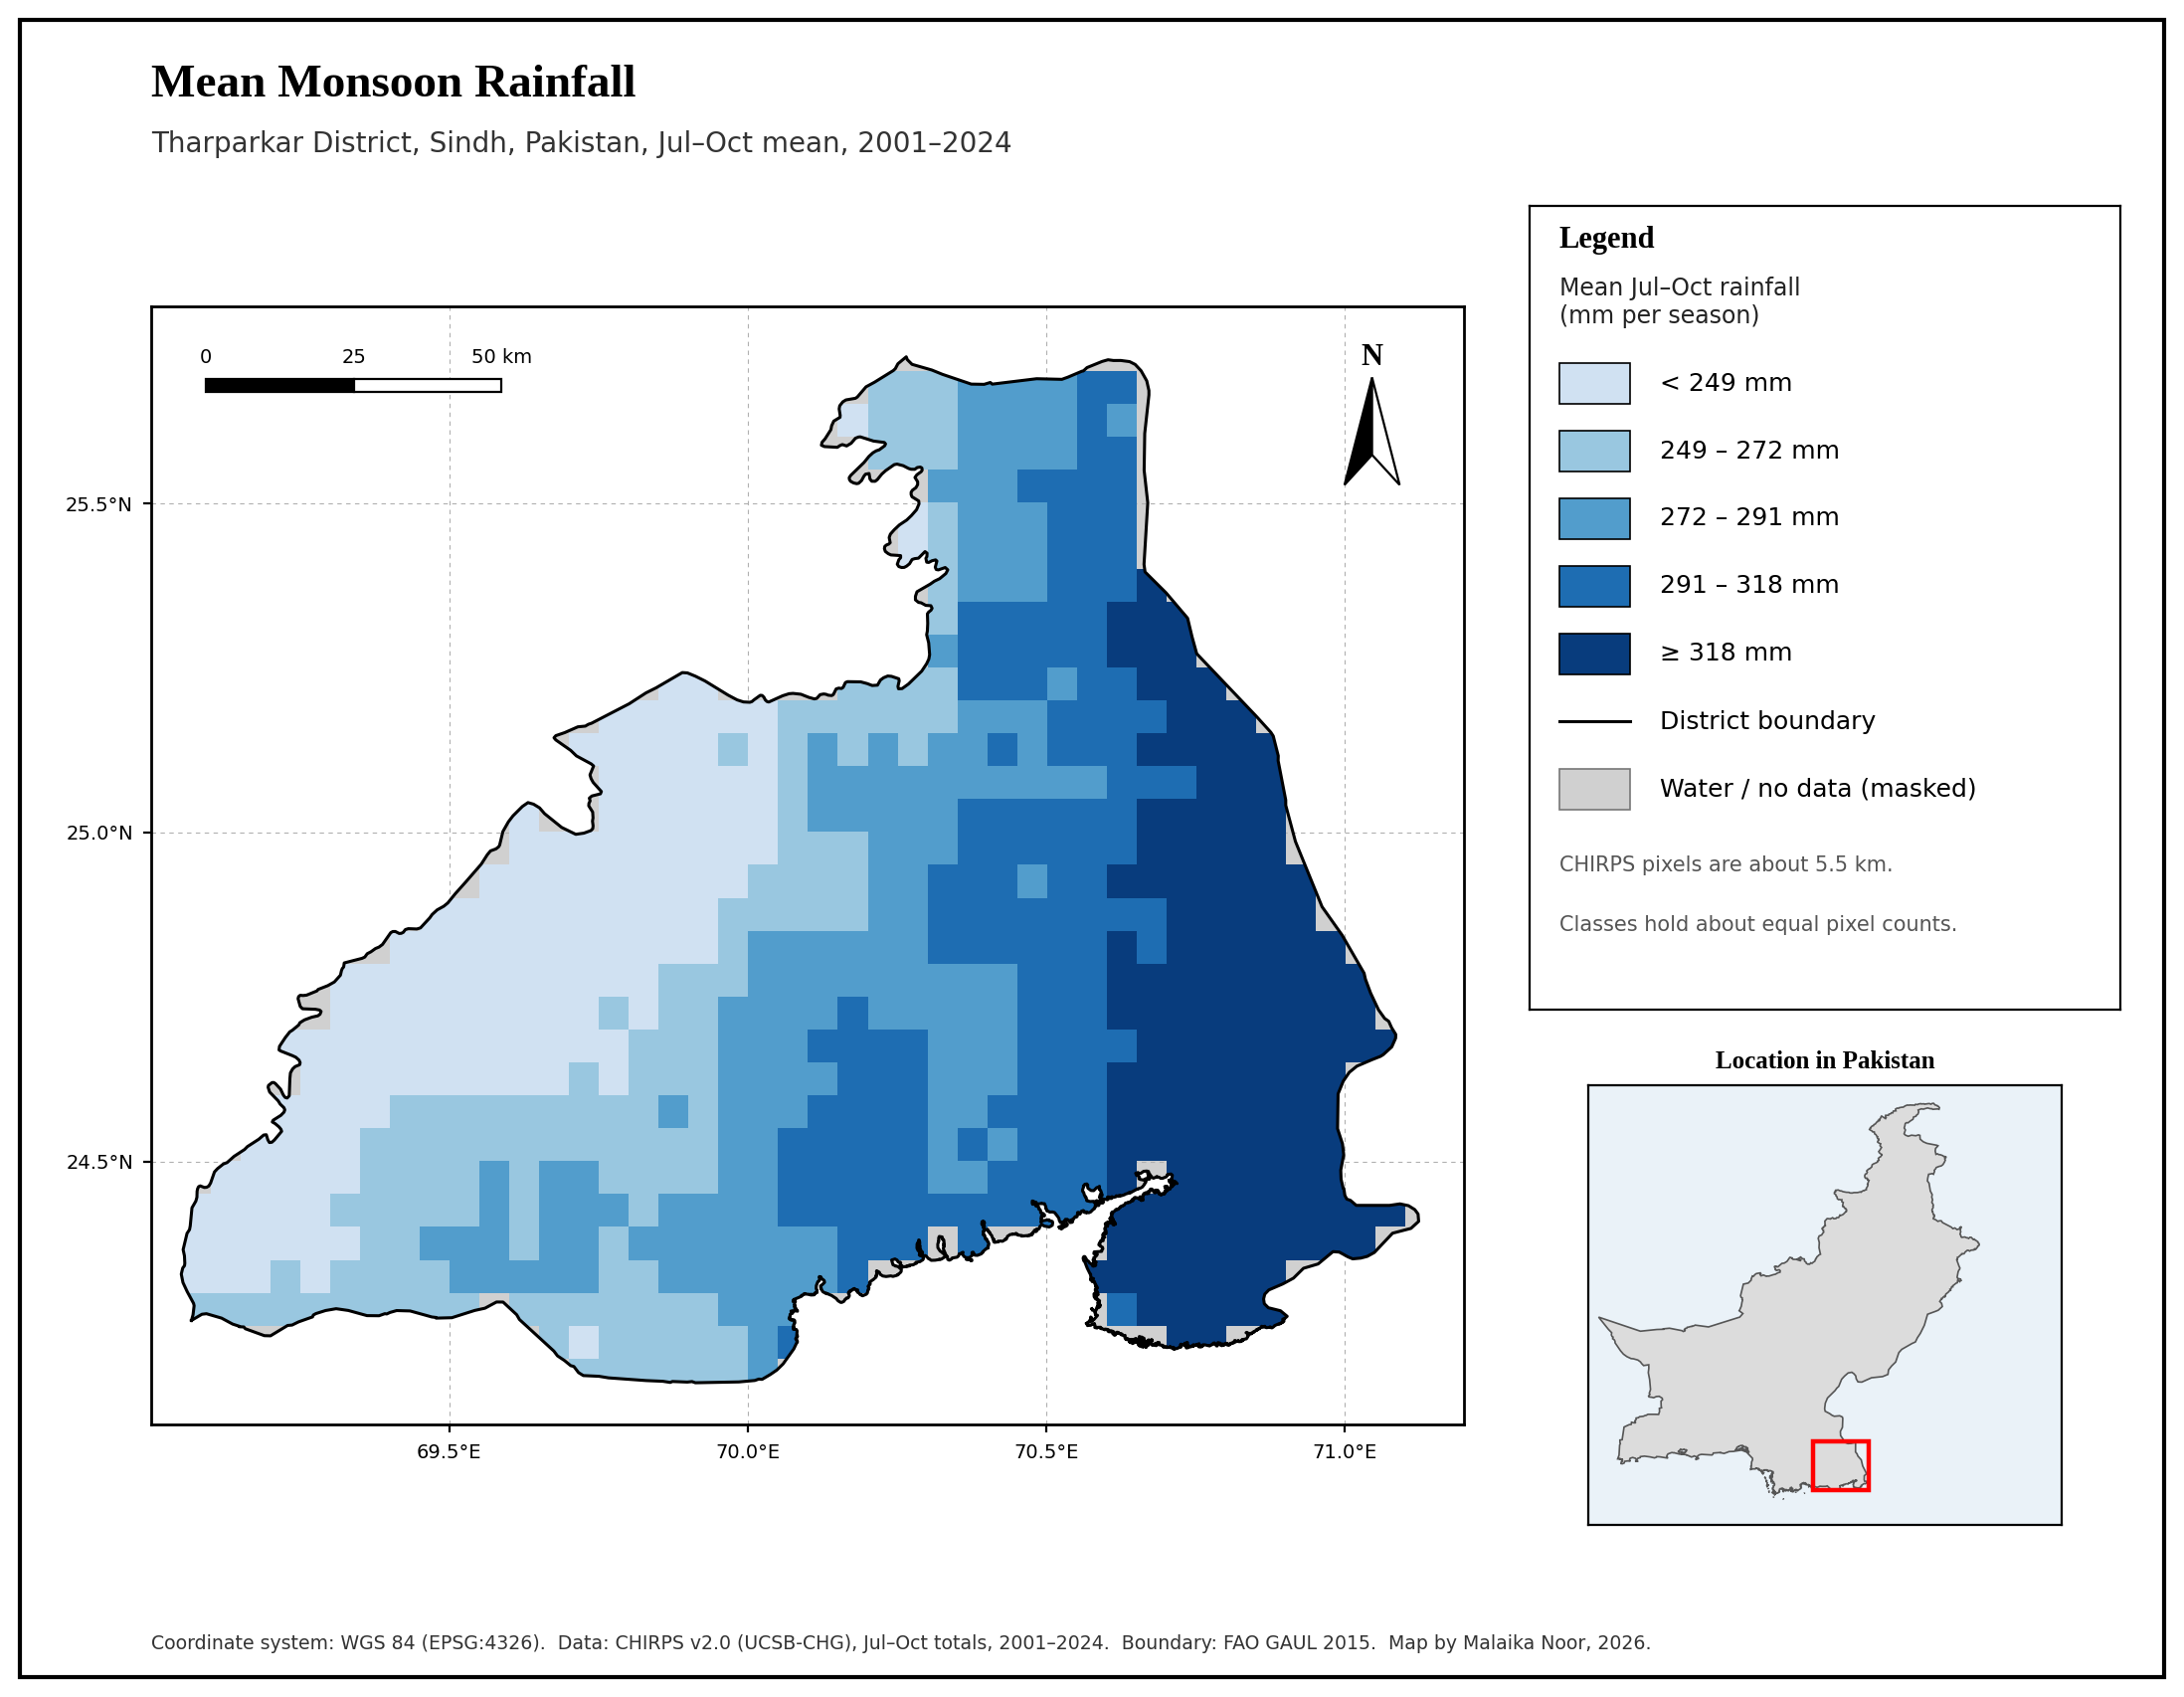

Saved outputs/map_01_mean_rainfall.png
ndvi_mean: 21648 pixels inside the district; 18888 valid-looking pixels outside it were dropped; 19 inside pixels with value <= 0 were set to no data
Mean NDVI min / 25% / median / 75% / max: [0.001 0.222 0.243 0.262 0.434]


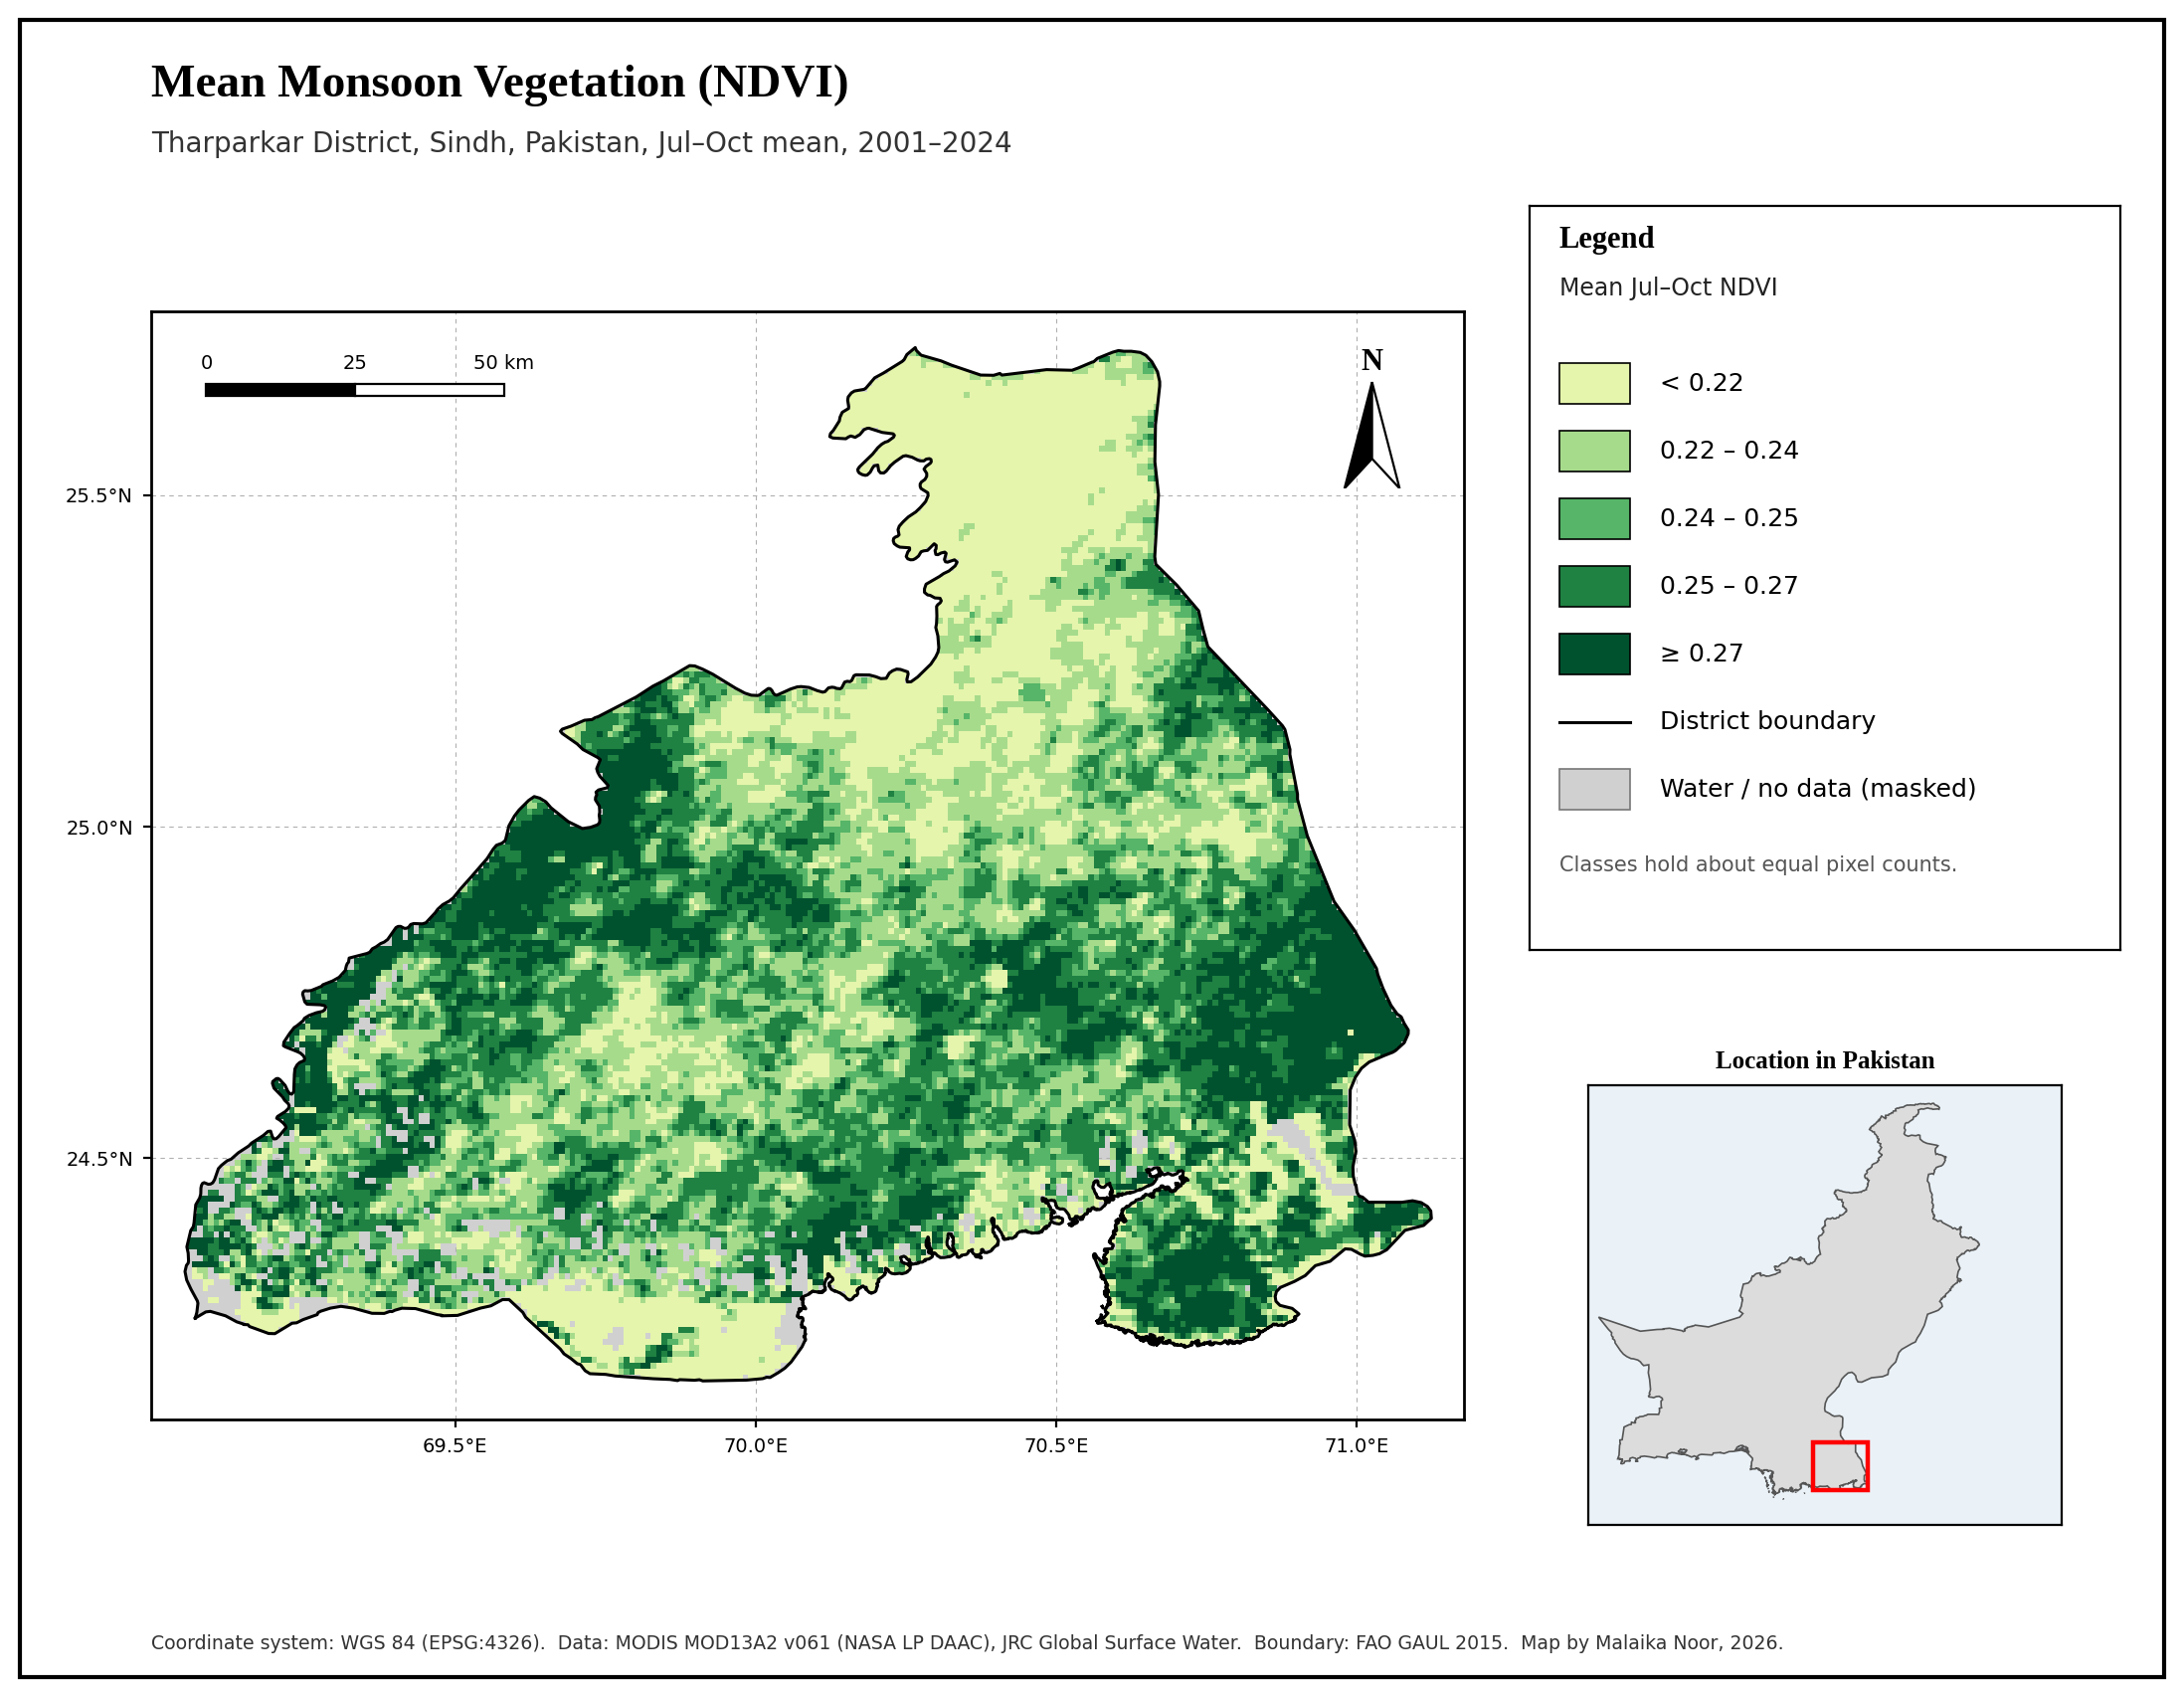

Saved outputs/map_02_mean_ndvi.png


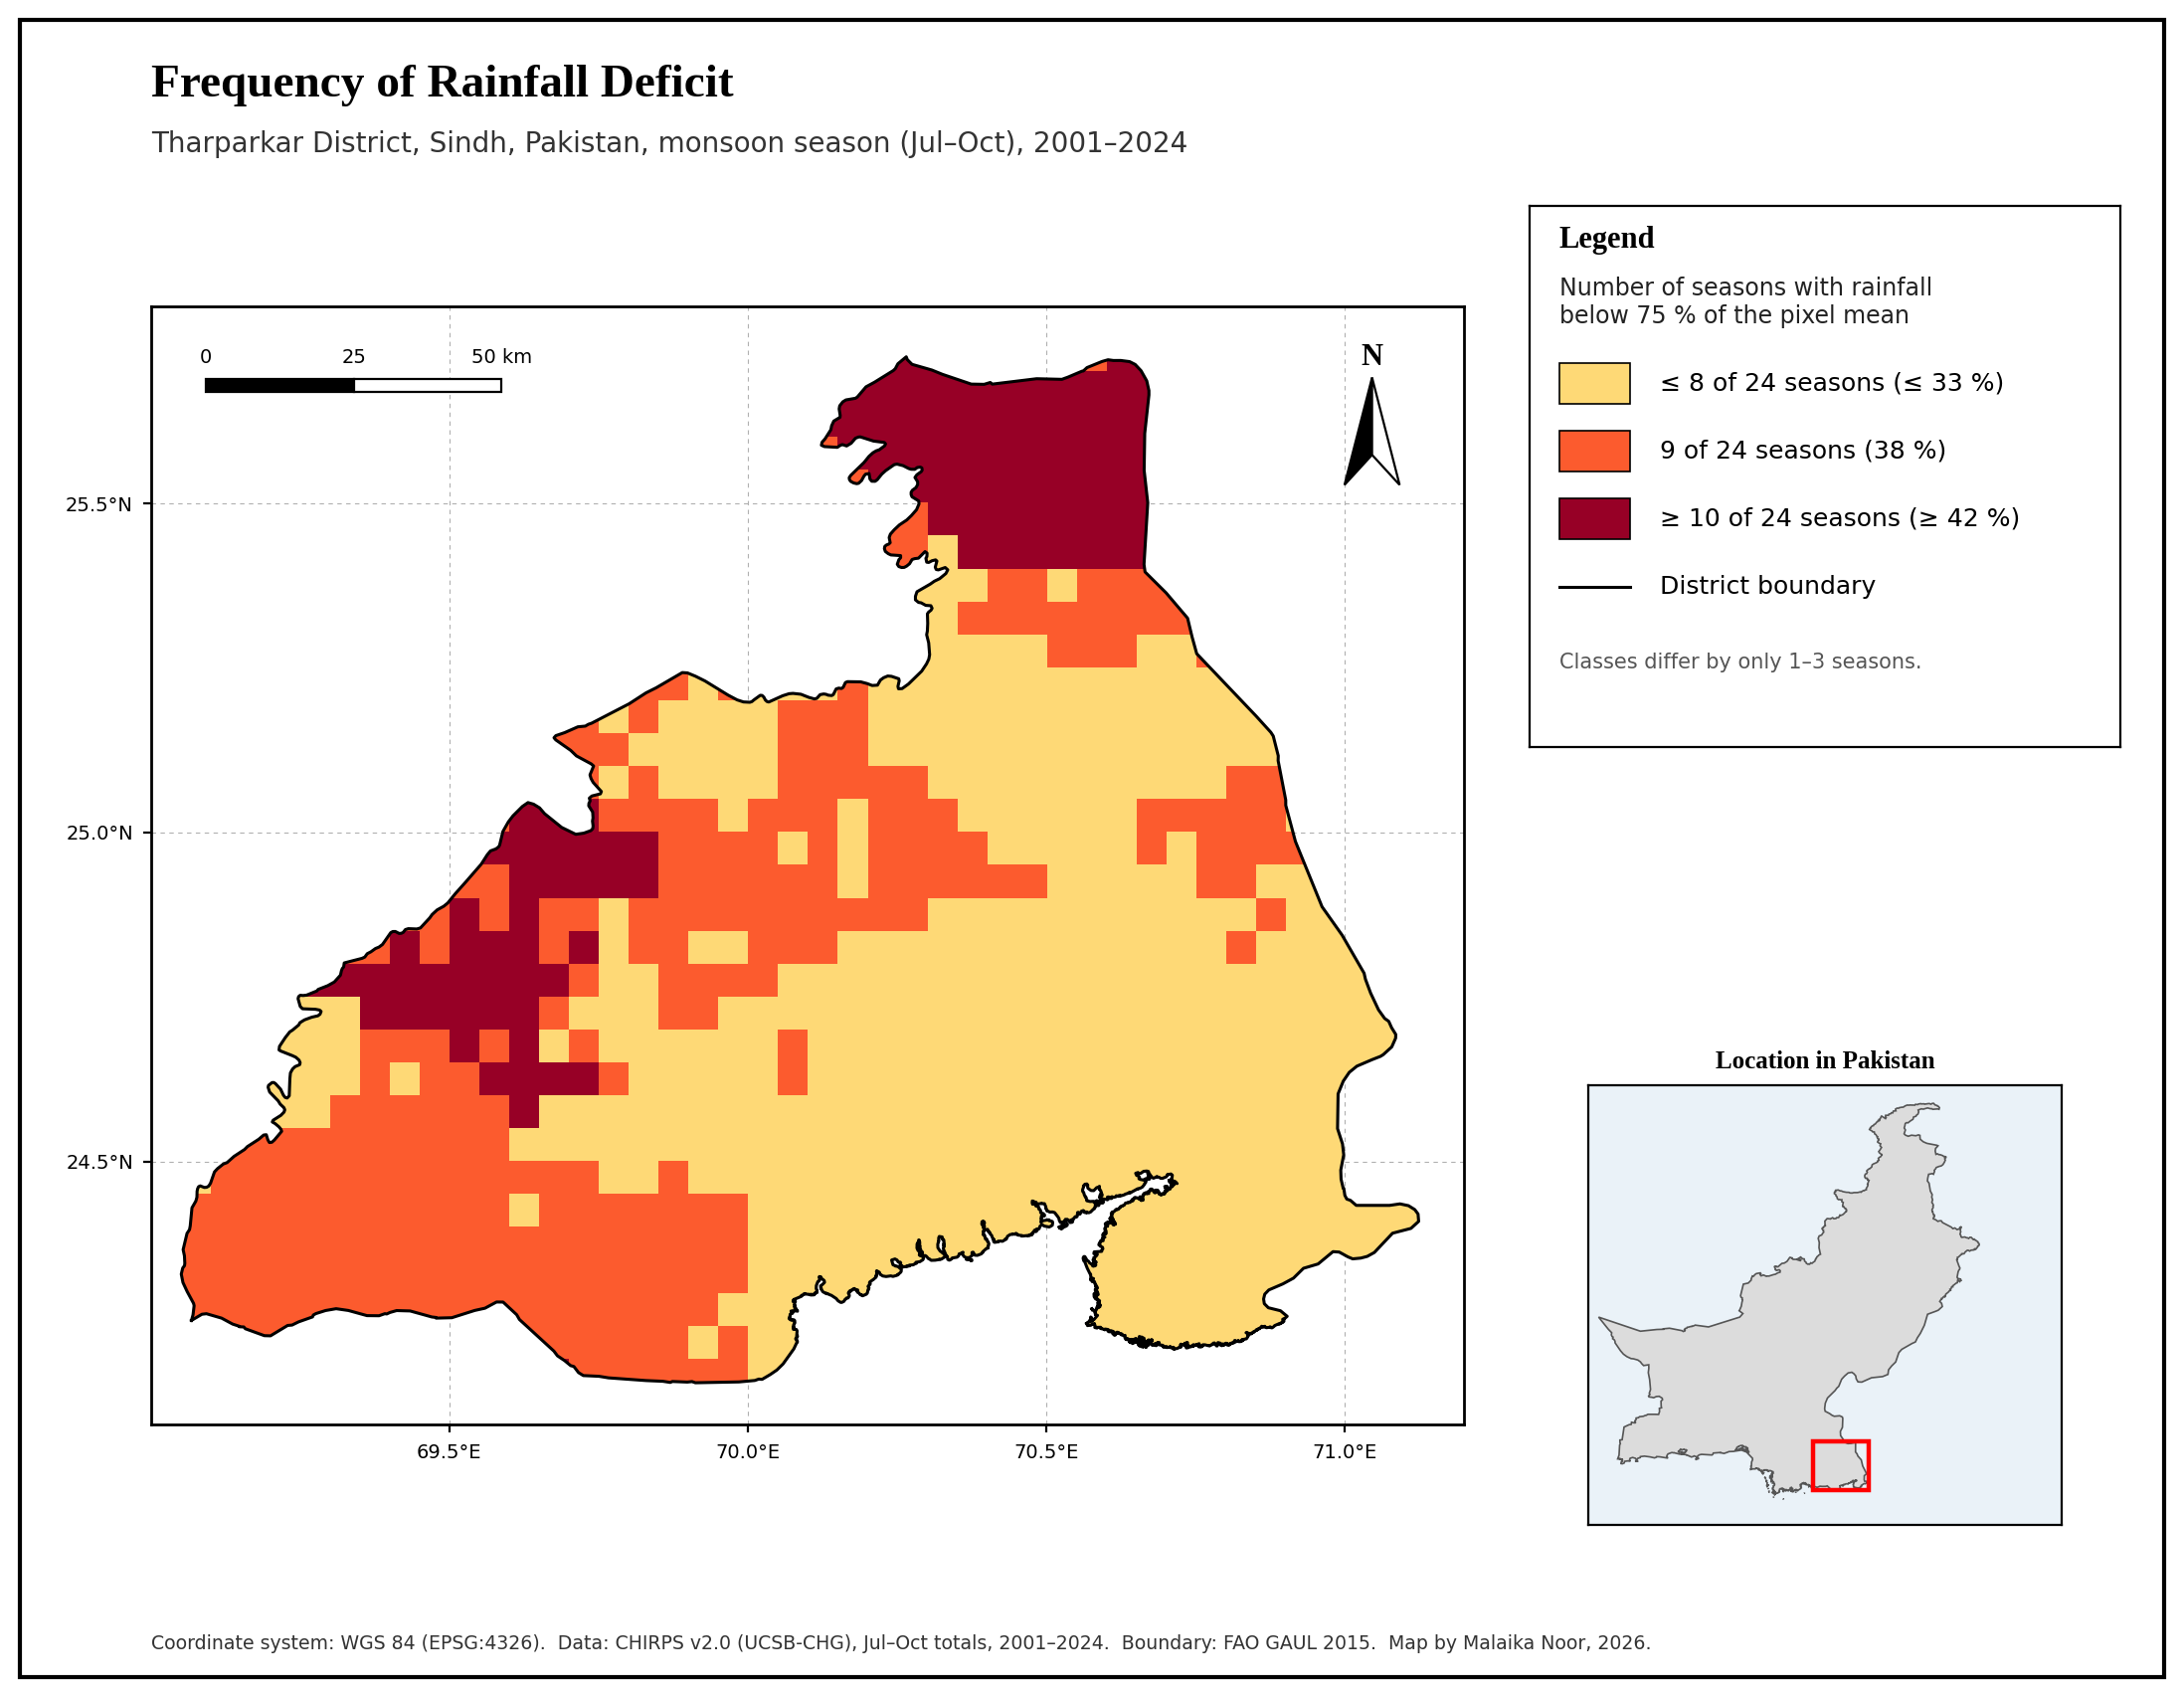

Saved outputs/map_03_rainfall_deficit_frequency.png


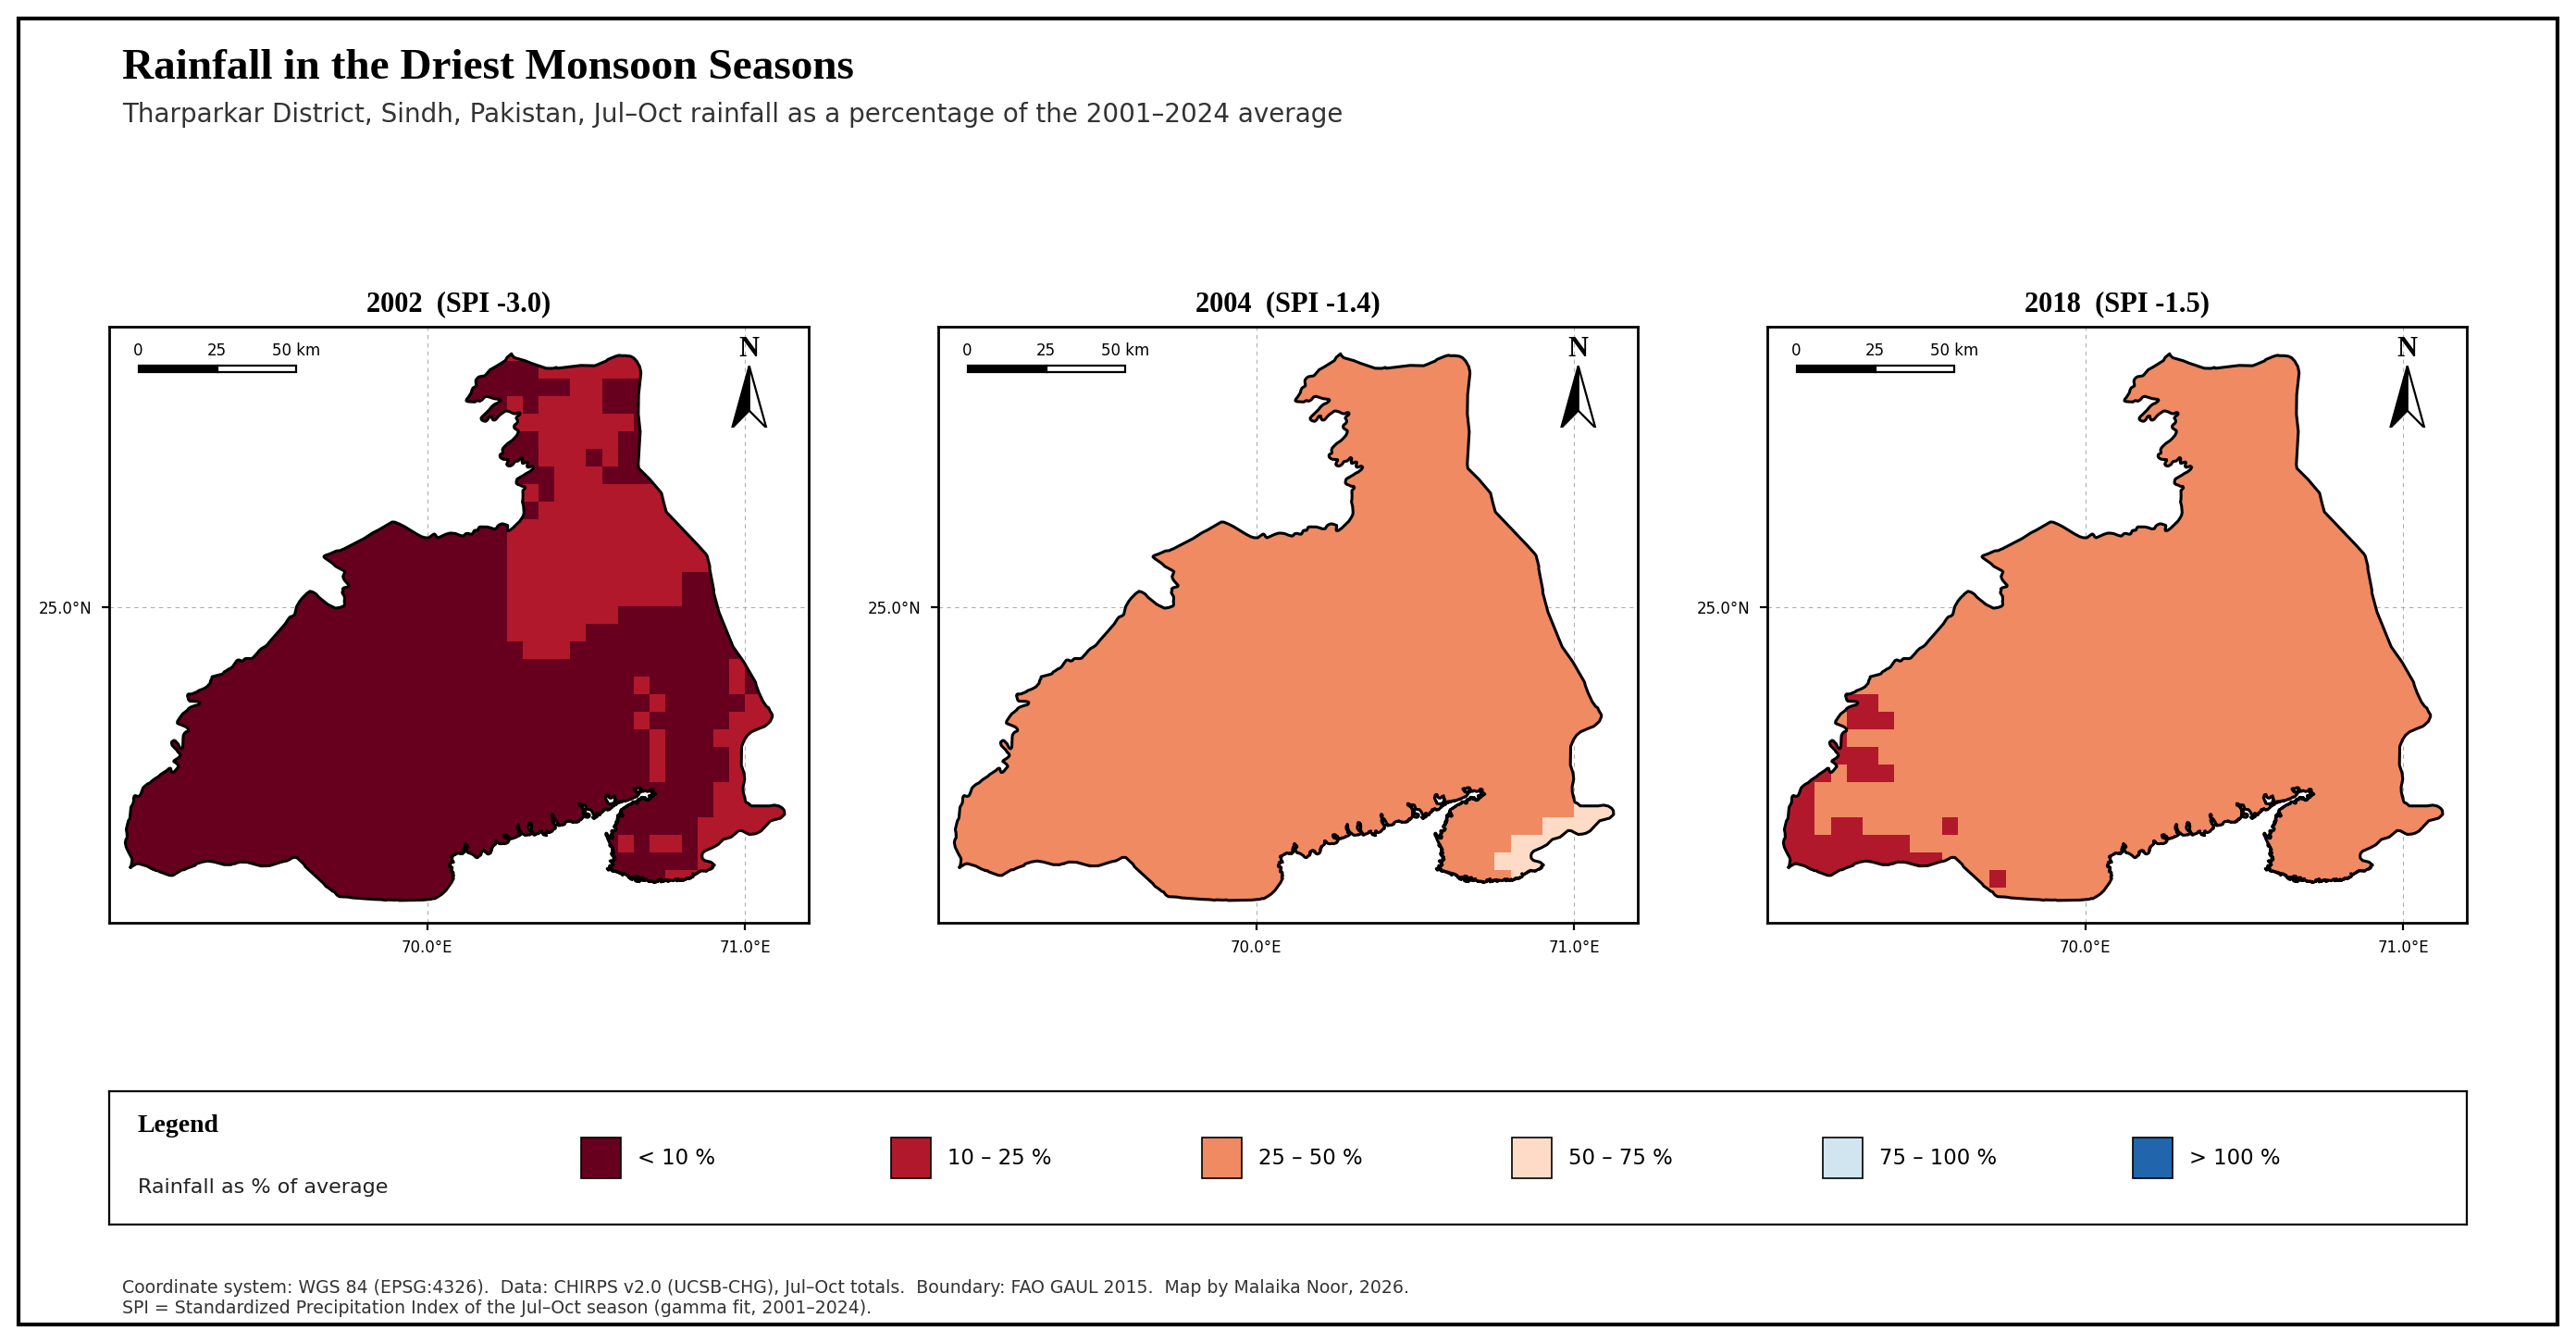

Saved outputs/map_04_rainfall_dry_seasons.png


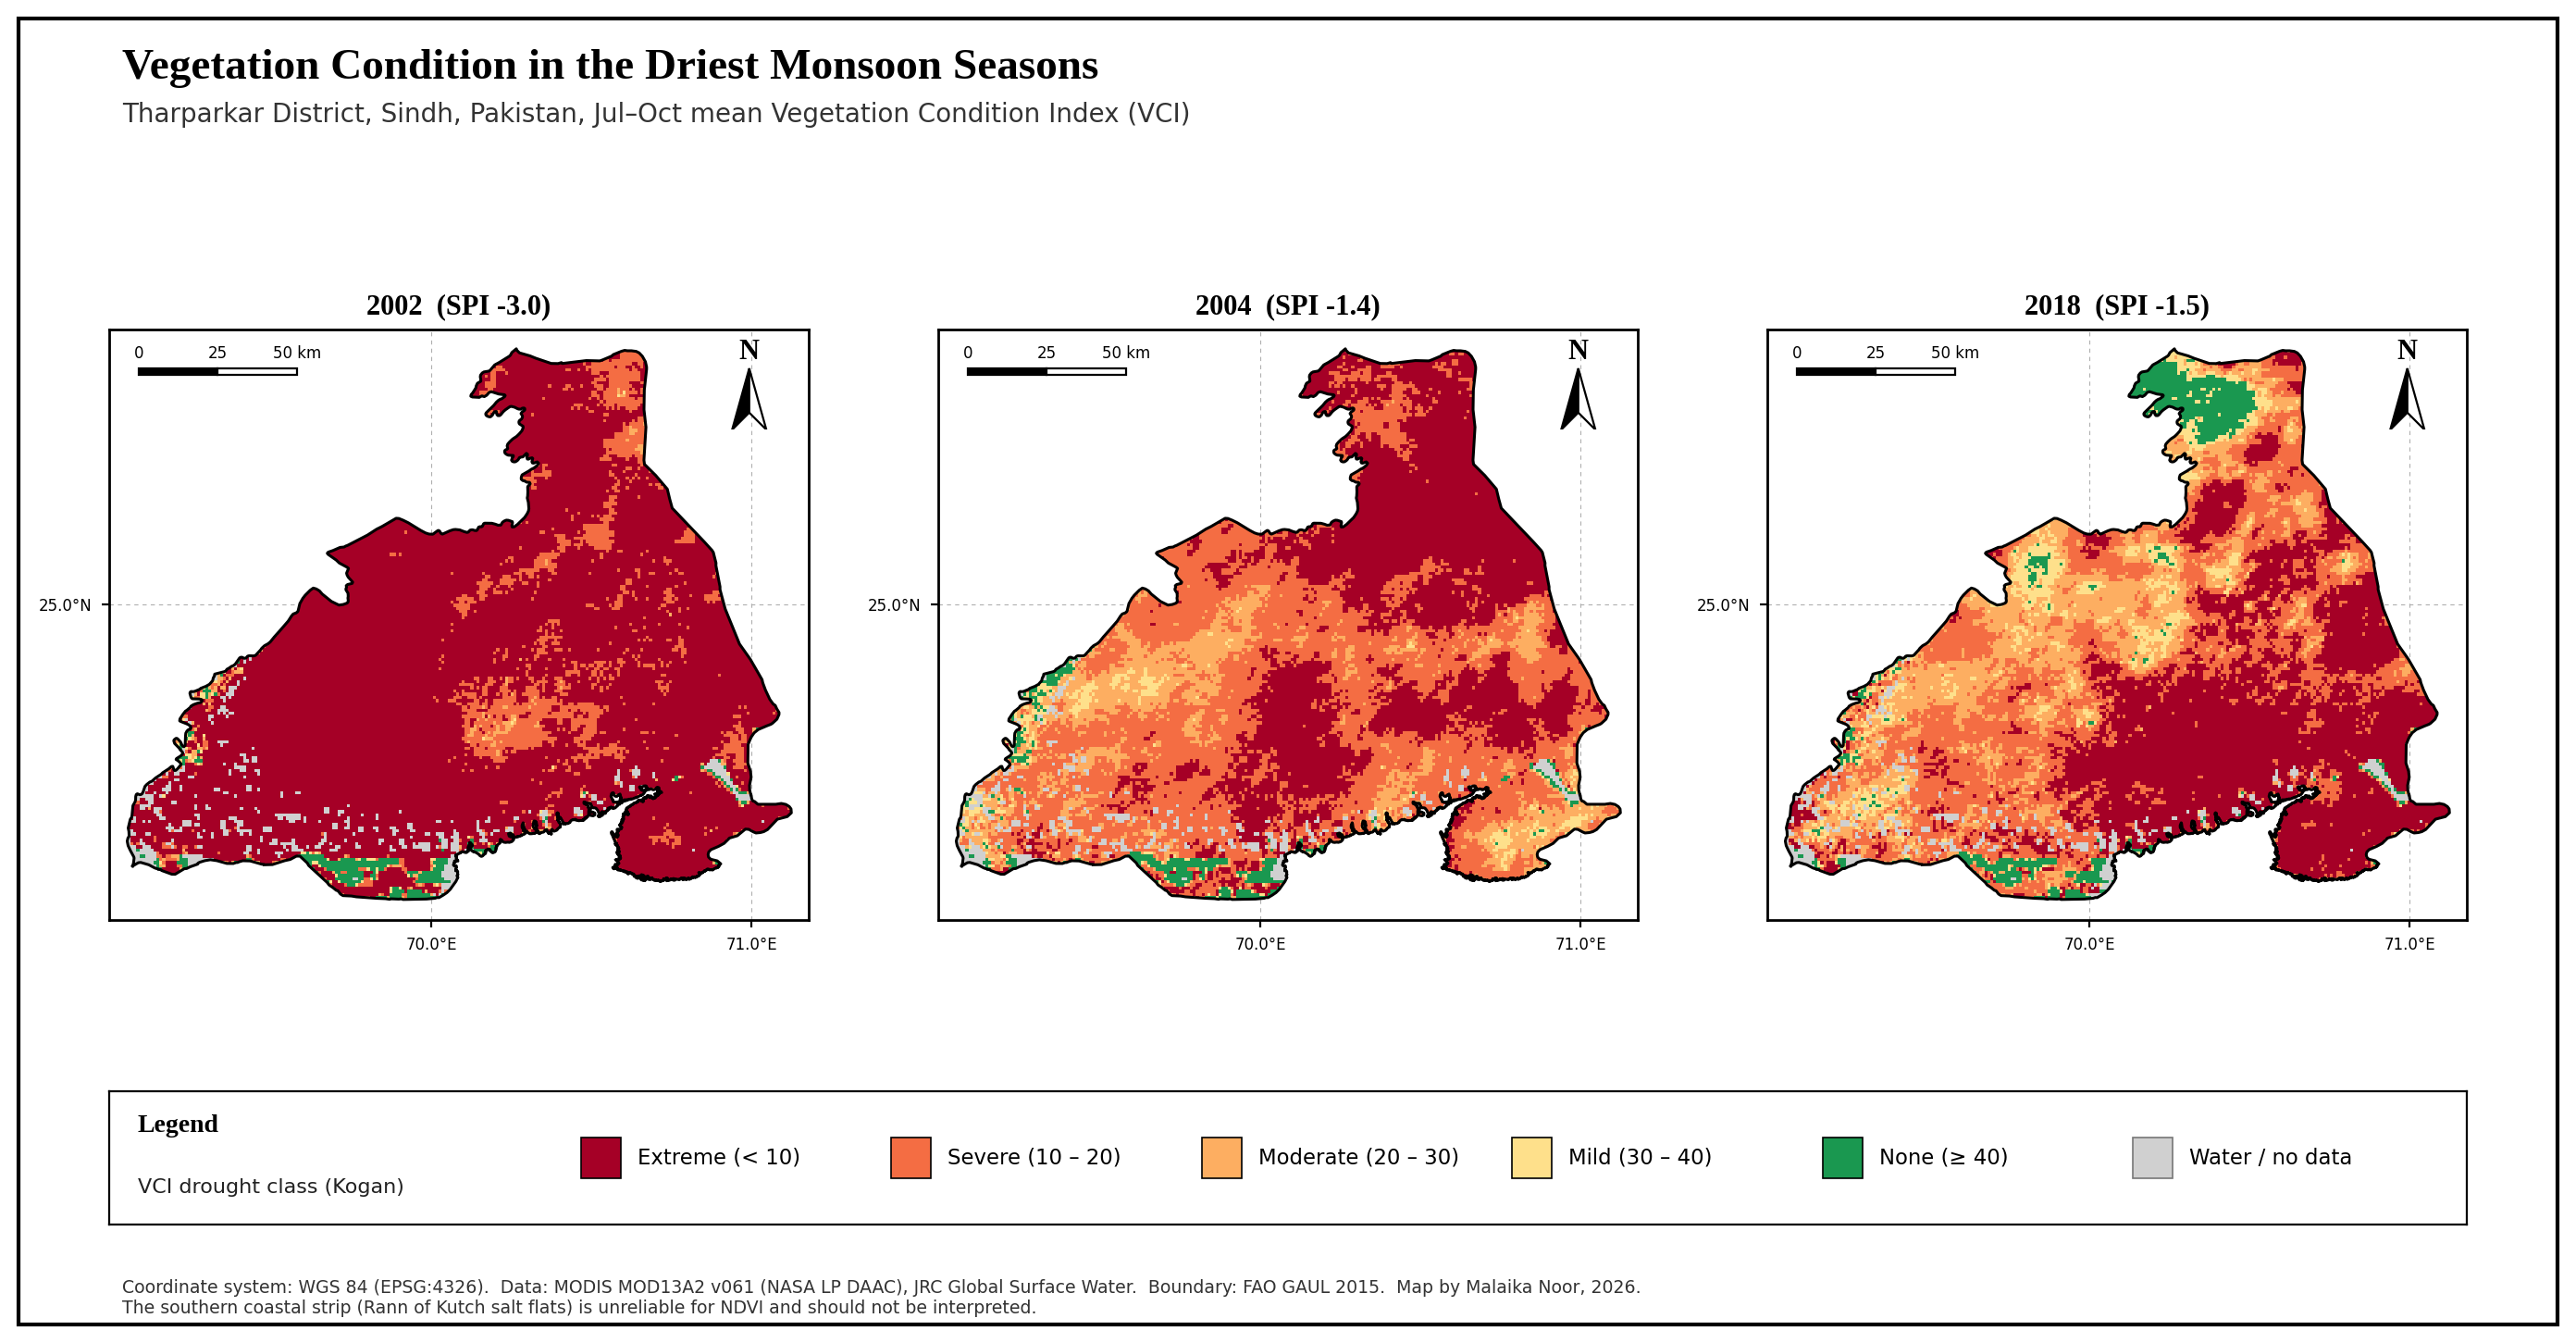

Saved outputs/map_05_vci_dry_seasons.png


In [ ]:
# ===== CELL 5 (final): cartographic map layouts =====
try:
    import rasterio
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio'])
    import rasterio
from matplotlib import font_manager
from matplotlib.patches import Rectangle, Polygon, PathPatch
from matplotlib.path import Path
from matplotlib.colors import ListedColormap, BoundaryNorm, to_hex
from matplotlib.ticker import FuncFormatter

AUTHOR = 'Malaika Noor'
SERIF = 'DejaVu Serif'
_names = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Times New Roman', 'Liberation Serif', 'Nimbus Roman', 'DejaVu Serif']:
    if _f in _names:
        SERIF = _f; break

# ---------- data helpers ----------
def read_layer(b):
    with rasterio.open(f'outputs/thar_{b}.tif') as src:
        a = src.read(1).astype(float); bnd = src.bounds
    a[a <= -9000] = np.nan
    return a, bnd

def all_rings(g):
    t = g['type']
    if t == 'GeometryCollection':
        for gg in g['geometries']:
            yield from all_rings(gg)
    elif t in ('Polygon', 'MultiPolygon'):
        polys = [g['coordinates']] if t == 'Polygon' else g['coordinates']
        for p in polys:
            yield np.array(p[0])[:, :2]

feats = districts.map(lambda f: f.simplify(100)).getInfo()['features']
bound_rings = [r for f in feats for r in all_rings(f['geometry'])]
verts, codes = [], []
for rr in bound_rings:
    verts += list(map(tuple, rr)) + [tuple(rr[0])]
    codes += [Path.MOVETO] + [Path.LINETO] * (len(rr) - 1) + [Path.CLOSEPOLY]
clip_path = Path(verts, codes)
try:
    pk_rings = list(all_rings(ee.FeatureCollection('FAO/GAUL/2015/level0')
                              .filter(ee.Filter.eq('ADM0_NAME', 'Pakistan'))
                              .geometry().simplify(2000).getInfo()))
except Exception as e:
    pk_rings = None; print('Pakistan outline skipped:', str(e)[:100])

def clean_layer(a, bnd, name, drop_nonpositive=False):
    """Keep only pixels whose centre lies inside the district; optionally treat values <= 0 as no data."""
    h, w = a.shape
    xs = bnd.left + (np.arange(w) + 0.5) * (bnd.right - bnd.left) / w
    ys = bnd.top - (np.arange(h) + 0.5) * (bnd.top - bnd.bottom) / h
    X, Y = np.meshgrid(xs, ys)
    inside = clip_path.contains_points(np.c_[X.ravel(), Y.ravel()]).reshape(h, w)
    a = a.copy()
    outside_valid = int(np.sum(np.isfinite(a) & ~inside))
    a[~inside] = np.nan
    n_inside = int(np.sum(inside))
    msg = f'{name}: {n_inside} pixels inside the district; {outside_valid} valid-looking pixels outside it were dropped'
    if drop_nonpositive:
        bad = np.isfinite(a) & (a <= 0)
        msg += f'; {int(bad.sum())} inside pixels with value <= 0 were set to no data'
        a[bad] = np.nan
    print(msg)
    return a

def quantile_classes(a, n, decimals, cmap, unit=''):
    """n classes holding roughly equal numbers of pixels; break values rounded to `decimals` places."""
    qs = np.nanpercentile(a, np.linspace(0, 100, n + 1)[1:-1])
    d = decimals
    inner = sorted(set(np.round(qs, d)))
    if len(inner) < n - 1:                      # rounding merged some breaks: use one more decimal
        d += 1
        inner = sorted(set(np.round(qs, d)))
    f = '{:.%df}' % max(d, 0)
    k = len(inner) + 1
    bins = [np.nanmin(a) - 1] + inner + [np.nanmax(a) + 1]
    cols = [to_hex(c) for c in cmap(np.linspace(0.2, 0.95, k))]
    labels = ([f'< {f.format(inner[0])}{unit}']
              + [f'{f.format(inner[i])} – {f.format(inner[i + 1])}{unit}' for i in range(k - 2)]
              + [f'≥ {f.format(inner[-1])}{unit}'])
    return bins, cols, labels

# ---------- drawing helpers ----------
def raster(ax, arr, bnd, bins, colors):
    """Pixels with no data / masked water show in light grey (matches the legend)."""
    ax.set_facecolor('white')
    ax.add_patch(PathPatch(clip_path, transform=ax.transData, fc='#d0d0d0', ec='none', lw=0, zorder=1))
    im = ax.imshow(np.ma.masked_invalid(arr), extent=[bnd.left, bnd.right, bnd.bottom, bnd.top],
                   origin='upper', cmap=ListedColormap(colors), norm=BoundaryNorm(bins, len(colors)),
                   interpolation='nearest', zorder=2)
    im.set_clip_path(PathPatch(clip_path, transform=ax.transData))

def finish_axes(ax, bnd, step, labelsize):
    midlat = (bnd.bottom + bnd.top) / 2
    ax.set_aspect(1 / np.cos(np.radians(midlat)))
    ax.set_xlim(bnd.left - 0.05, bnd.right + 0.05); ax.set_ylim(bnd.bottom - 0.05, bnd.top + 0.05)
    ax.set_xticks(np.arange(np.ceil(bnd.left / step) * step, bnd.right, step))
    ax.set_yticks(np.arange(np.ceil(bnd.bottom / step) * step, bnd.top, step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.1f}°E'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.1f}°N'))
    ax.tick_params(labelsize=labelsize, length=3)
    ax.grid(color='#b0b0b0', ls=(0, (4, 4)), lw=0.4, zorder=3)
    for s in ax.spines.values(): s.set_linewidth(1.0)
    for rr in bound_rings:
        ax.plot(rr[:, 0], rr[:, 1], color='black', lw=1.1, zorder=4)

def scale_bar(ax, bnd, km=25, fs=7):
    midlat = (bnd.bottom + bnd.top) / 2
    seg = km / (111.32 * np.cos(np.radians(midlat)))
    W, H = bnd.right - bnd.left, bnd.top - bnd.bottom
    sx, sy, h = bnd.left + 0.02 * W, bnd.top - 0.05 * H, 0.012 * H
    ax.add_patch(Rectangle((sx, sy), seg, h, fc='black', ec='black', lw=0.8, zorder=8))
    ax.add_patch(Rectangle((sx + seg, sy), seg, h, fc='white', ec='black', lw=0.8, zorder=8))
    for i, lab in enumerate(['0', f'{km}', f'{2 * km} km']):
        ax.text(sx + i * seg, sy + 1.9 * h, lab, fontsize=fs, ha='center', va='bottom', zorder=8)

def north_arrow(ax, pos):
    na = ax.inset_axes(pos); na.axis('off'); na.set_xlim(0, 1); na.set_ylim(0, 1.25)
    na.add_patch(Polygon([(0.5, 1), (0.15, 0), (0.5, 0.28)], fc='black', ec='black', lw=0.8))
    na.add_patch(Polygon([(0.5, 1), (0.85, 0), (0.5, 0.28)], fc='white', ec='black', lw=0.8))
    na.text(0.5, 1.05, 'N', ha='center', va='bottom', fontsize=11, fontweight='bold', fontfamily=SERIF)

def legend_box(fig, title, items, notes=(), nodata=False):
    rows = len(items) + 1 + (1 if nodata else 0)
    height = 0.125 + 0.04 * rows + 0.035 * len(notes)
    lg = fig.add_axes([0.70, 0.88 - height, 0.27, height])
    lg.set_xlim(0, 1); lg.set_ylim(0, height); lg.set_xticks([]); lg.set_yticks([])
    for s in lg.spines.values(): s.set_linewidth(0.8)
    lg.text(0.05, height - 0.012, 'Legend', fontsize=11, fontweight='bold', fontfamily=SERIF, va='top')
    lg.text(0.05, height - 0.042, title, fontsize=8.5, va='top', color='#222222')
    y = height - 0.105
    for col, lab in items:
        lg.add_patch(Rectangle((0.05, y - 0.012), 0.12, 0.024, fc=col, ec='black', lw=0.6))
        lg.text(0.22, y, lab, fontsize=9, va='center'); y -= 0.04
    lg.plot([0.05, 0.17], [y, y], color='black', lw=1.1)
    lg.text(0.22, y, 'District boundary', fontsize=9, va='center'); y -= 0.04
    if nodata:
        lg.add_patch(Rectangle((0.05, y - 0.012), 0.12, 0.024, fc='#d0d0d0', ec='#777777', lw=0.6))
        lg.text(0.22, y, 'Water / no data (masked)', fontsize=9, va='center'); y -= 0.04
    for nt in notes:
        lg.text(0.05, y - 0.005, nt, fontsize=7.5, va='center', color='#555555'); y -= 0.035

def locator(fig, rect, bnd):
    ins = fig.add_axes(rect); ins.set_facecolor('#eaf2f8')
    ins.set_xlim(60.5, 78.5); ins.set_ylim(23.0, 37.5); ins.set_aspect(1 / np.cos(np.radians(30)))
    ins.set_xticks([]); ins.set_yticks([])
    ins.set_title('Location in Pakistan', fontsize=9, fontweight='bold', fontfamily=SERIF)
    if pk_rings:
        for rr in pk_rings:
            ins.add_patch(Polygon(rr, closed=True, fc='#dcdcdc', ec='#555555', lw=0.6))
    ins.add_patch(Rectangle((bnd.left, bnd.bottom), bnd.right - bnd.left, bnd.top - bnd.bottom,
                            fc='none', ec='red', lw=1.6))

def titles_and_frame(fig, title, subtitle, src, note=''):
    xl = 0.05 if fig.get_figwidth() > 12 else 0.07
    fig.text(xl, 0.945, title, fontsize=17, fontweight='bold', fontfamily=SERIF)
    fig.text(xl, 0.912, subtitle, fontsize=10, color='#333333')
    foot = f'Coordinate system: WGS 84 (EPSG:4326).  Data: {src}.  Boundary: FAO GAUL 2015.  Map by {AUTHOR}, 2026.'
    if note: foot += '\n' + note
    fig.text(xl, 0.03, foot, fontsize=6.8, color='#333333', va='center')
    fig.add_artist(Rectangle((0.01, 0.01), 0.98, 0.98, transform=fig.transFigure, fill=False, ec='black', lw=1.5))

# ---------- layouts ----------
def single_map(arr, bnd, fname, title, subtitle, leg_title, bins, colors, labels, src, notes=(), nodata=False):
    fig = plt.figure(figsize=(11, 8.5), dpi=200, facecolor='white')
    ax = fig.add_axes([0.07, 0.10, 0.60, 0.78])
    raster(ax, arr, bnd, bins, colors); finish_axes(ax, bnd, 0.5, 7)
    scale_bar(ax, bnd); north_arrow(ax, [0.90, 0.84, 0.06, 0.12])
    legend_box(fig, leg_title, list(zip(colors, labels)), notes, nodata)
    locator(fig, [0.70, 0.10, 0.27, 0.26], bnd)
    titles_and_frame(fig, title, subtitle, src)
    fig.savefig(fname, dpi=300, facecolor='white'); plt.show(); print('Saved', fname)

def panel_map(items, fname, title, subtitle, leg_title, bins, colors, labels, src, note='', nodata=False):
    n = len(items); gap = 0.05; w = (0.91 - gap * (n - 1)) / n
    fig = plt.figure(figsize=(14, 7.2), dpi=200, facecolor='white')
    for i, (arr, bnd, ptitle) in enumerate(items):
        ax = fig.add_axes([0.045 + i * (w + gap), 0.25, w, 0.57])
        raster(ax, arr, bnd, bins, colors); finish_axes(ax, bnd, 1.0, 6)
        scale_bar(ax, bnd, fs=6); north_arrow(ax, [0.88, 0.83, 0.07, 0.13])
        ax.set_title(ptitle, fontsize=11, fontweight='bold', fontfamily=SERIF, pad=6)
    lg = fig.add_axes([0.045, 0.085, 0.91, 0.10]); lg.set_xlim(0, 1); lg.set_ylim(0, 1)
    lg.set_xticks([]); lg.set_yticks([])
    for s in lg.spines.values(): s.set_linewidth(0.8)
    lg.text(0.012, 0.74, 'Legend', fontsize=10, fontweight='bold', fontfamily=SERIF, va='center')
    lg.text(0.012, 0.28, leg_title, fontsize=8, va='center', color='#222222')
    ncell = len(colors) + (1 if nodata else 0)
    x0 = 0.20; wl = 0.79 / ncell
    for i, (col, lab) in enumerate(zip(colors, labels)):
        xx = x0 + i * wl
        lg.add_patch(Rectangle((xx, 0.35), 0.017, 0.30, fc=col, ec='black', lw=0.6))
        lg.text(xx + 0.024, 0.50, lab, fontsize=8.2, va='center')
    if nodata:
        xx = x0 + len(colors) * wl
        lg.add_patch(Rectangle((xx, 0.35), 0.017, 0.30, fc='#d0d0d0', ec='#777777', lw=0.6))
        lg.text(xx + 0.024, 0.50, 'Water / no data', fontsize=8.2, va='center')
    titles_and_frame(fig, title, subtitle, src, note)
    fig.savefig(fname, dpi=300, facecolor='white'); plt.show(); print('Saved', fname)

# ---------- build the five maps ----------
spi = d.set_index('year')['SPI_JulOct']
DRY = sorted(spi.loc[DRY_YEARS].nsmallest(3).index.tolist())     # up to three driest seasons, from Cell 4
N_SEASONS = END_YEAR - START_YEAR + 1
SUB = 'Tharparkar District, Sindh, Pakistan'
CH = 'CHIRPS v2.0 (UCSB-CHG), Jul–Oct totals'
MO = 'MODIS MOD13A2 v061 (NASA LP DAAC), JRC Global Surface Water'

# Map 1: mean rainfall (classes hold about equal numbers of pixels, so every class appears on the map)
a, b = read_layer('rain_mean')
a = clean_layer(a, b, 'rain_mean', drop_nonpositive=True)
print('Mean rainfall (mm) min / 25% / median / 75% / max:', np.round(np.nanpercentile(a, [0, 25, 50, 75, 100]), 1))
bins, cols, labs = quantile_classes(a, 5, 0, plt.cm.Blues, ' mm')
single_map(a, b, 'outputs/map_01_mean_rainfall.png', 'Mean Monsoon Rainfall',
           SUB + f', Jul–Oct mean, {START_YEAR}–{END_YEAR}', 'Mean Jul–Oct rainfall\n(mm per season)',
           bins, cols, labs, CH + f', {START_YEAR}–{END_YEAR}',
              notes=('CHIRPS pixels are about 5.5 km.', 'Classes hold about equal pixel counts.'), nodata=True)

# Map 2: mean NDVI
a, b = read_layer('ndvi_mean')
a = clean_layer(a, b, 'ndvi_mean', drop_nonpositive=True)
print('Mean NDVI min / 25% / median / 75% / max:', np.round(np.nanpercentile(a, [0, 25, 50, 75, 100]), 3))
bins, cols, labs = quantile_classes(a, 5, 2, plt.cm.YlGn)
single_map(a, b, 'outputs/map_02_mean_ndvi.png', 'Mean Monsoon Vegetation (NDVI)',
           SUB + f', Jul–Oct mean, {START_YEAR}–{END_YEAR}', 'Mean Jul–Oct NDVI',
           bins, cols, labs, MO, notes=('Classes hold about equal pixel counts.',), nodata=True)

# Map 3: how often rainfall was well below average (classes = number of seasons)
a, b = read_layer('def_freq')
k = np.round(a * N_SEASONS / 100)
cols = [to_hex(c) for c in plt.cm.YlOrRd([0.25, 0.6, 0.95])]
single_map(k, b, 'outputs/map_03_rainfall_deficit_frequency.png', 'Frequency of Rainfall Deficit',
           SUB + f', monsoon season (Jul–Oct), {START_YEAR}–{END_YEAR}',
           'Number of seasons with rainfall\nbelow 75 % of the pixel mean',
           [-0.5, 8.5, 9.5, N_SEASONS + 0.5], cols,
           [f'≤ 8 of {N_SEASONS} seasons (≤ 33 %)', f'9 of {N_SEASONS} seasons (38 %)',
            f'≥ 10 of {N_SEASONS} seasons (≥ 42 %)'],
           CH + f', {START_YEAR}–{END_YEAR}', notes=('Classes differ by only 1–3 seasons.',))

# Map 4: rainfall in the driest seasons
items = [(*read_layer(f'rainpct_{y}'), f'{y}  (SPI {spi[y]:.1f})') for y in DRY]
panel_map(items, 'outputs/map_04_rainfall_dry_seasons.png', 'Rainfall in the Driest Monsoon Seasons',
          SUB + f', Jul–Oct rainfall as a percentage of the {START_YEAR}–{END_YEAR} average',
          'Rainfall as % of average',
          [-0.01, 10, 25, 50, 75, 100, 10000],
          ['#67001f', '#b2182b', '#ef8a62', '#fddbc7', '#d1e5f0', '#2166ac'],
          ['< 10 %', '10 – 25 %', '25 – 50 %', '50 – 75 %', '75 – 100 %', '> 100 %'],
          CH, note=f'SPI = Standardized Precipitation Index of the Jul–Oct season (gamma fit, {START_YEAR}–{END_YEAR}).')

# Map 5: vegetation condition in the driest seasons
items = [(*read_layer(f'vci_{y}'), f'{y}  (SPI {spi[y]:.1f})') for y in DRY]
panel_map(items, 'outputs/map_05_vci_dry_seasons.png', 'Vegetation Condition in the Driest Monsoon Seasons',
          SUB + ', Jul–Oct mean Vegetation Condition Index (VCI)', 'VCI drought class (Kogan)',
          [-0.01, 10, 20, 30, 40, 100.01],
          ['#a50026', '#f46d43', '#fdae61', '#fee08b', '#1a9850'],
          ['Extreme (< 10)', 'Severe (10 – 20)', 'Moderate (20 – 30)', 'Mild (30 – 40)', 'None (≥ 40)'],
          MO, note='The southern coastal strip (Rann of Kutch salt flats) is unreliable for NDVI and should not be interpreted.',
          nodata=True)

Census-based estimate for 2020 (interpolated): 1,718,041
VCI grid: 175 x 232 | pixel size (deg): 0.00898


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


WorldPop 2020 district total (calculated in Earth Engine): 1,290,684
Downloaded 100 m population raster: 1751 x 2320
WorldPop total on the 1 km grid (inside district): 1,285,219
CHECK  grid total / Earth Engine total = 0.996   (should be close to 1.00)
WorldPop / census-2020 estimate = 0.75  (scale factor to census: 1.34)
vci_2002: 21648 pixels inside the district; 18885 valid-looking pixels outside it were dropped
vci_2004: 21648 pixels inside the district; 18882 valid-looking pixels outside it were dropped
vci_2018: 21648 pixels inside the district; 18883 valid-looking pixels outside it were dropped
 Year  SPI                VCI class  Pop WorldPop 2020  Pop scaled to census  Share of district pop (%)
 2002 -3.0            Extreme (<10)            1061320               1418740                       82.6
 2002 -3.0           Severe (10-20)             165781                221611                       12.9
 2002 -3.0         Moderate (20-30)              14367                 19205   

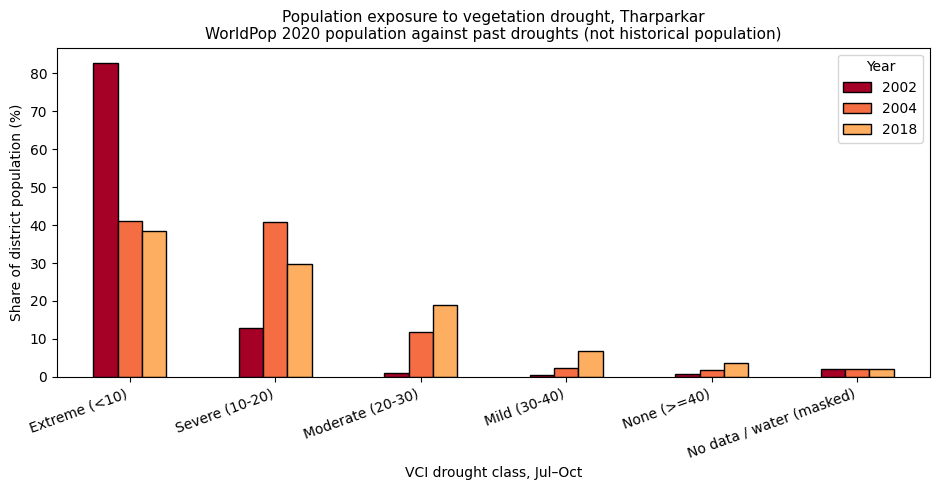

In [ ]:
# ===== CELL 6 (v5): population exposure to VCI drought classes =====
import io, zipfile, requests
import pandas as pd
from rasterio.io import MemoryFile

# Census anchors (Pakistan Bureau of Statistics), used only to scale WorldPop and for a sanity check
C2017, C2023 = 1647036, 1778407
CENSUS_2020 = C2017 * (C2023 / C2017) ** ((2020.5 - 2017.2) / (2023.2 - 2017.2))   # interpolated
print(f'Census-based estimate for 2020 (interpolated): {CENSUS_2020:,.0f}')

# 1) VCI grid = template
with rasterio.open('outputs/thar_vci_2002.tif') as src:
    T, H, W, CRS, BND = src.transform, src.height, src.width, src.crs, src.bounds
print('VCI grid:', H, 'x', W, '| pixel size (deg):', round(T.a, 5))

# 2) WorldPop 100 m (2020): district total in Earth Engine + the 100 m raster itself
wp = (ee.ImageCollection('WorldPop/GP/100m/pop')
      .filter(ee.Filter.eq('year', 2020)).filter(ee.Filter.eq('country', 'PAK')))
pop = wp.mosaic().select('population').setDefaultProjection(wp.first().projection())
ee_total = pop.reduceRegion(ee.Reducer.sum(), roi, 100, maxPixels=1e10,
                            tileScale=8).getInfo()['population']
print(f'WorldPop 2020 district total (calculated in Earth Engine): {ee_total:,.0f}')

region = ee.Geometry.Rectangle([BND.left, BND.bottom, BND.right, BND.top], 'EPSG:4326', False)
url = (pop.clip(roi).unmask(0).toFloat()
       .getDownloadURL({'region': region, 'crs': 'EPSG:4326', 'scale': 100, 'format': 'GEO_TIFF'}))
content = requests.get(url).content
if content[:2] == b'PK':
    z = zipfile.ZipFile(io.BytesIO(content))
    content = z.read([n for n in z.namelist() if n.endswith('.tif')][0])

# 3) Add the 100 m pixels into the 1 km VCI grid by position (totals are preserved exactly)
with MemoryFile(content) as mf, mf.open() as ds:
    a = ds.read(1).astype('float64'); sx = ds.transform
    print('Downloaded 100 m population raster:', ds.height, 'x', ds.width)
a[~np.isfinite(a) | (a < 0)] = 0
cs, rs = np.meshgrid(np.arange(a.shape[1]), np.arange(a.shape[0]))
Xs = sx.c + (cs + 0.5) * sx.a
Ys = sx.f + (rs + 0.5) * sx.e
cc = np.floor((Xs - T.c) / T.a).astype(int)
rr = np.floor((Ys - T.f) / T.e).astype(int)
ok = (cc >= 0) & (cc < W) & (rr >= 0) & (rr < H)
P = np.bincount(rr[ok] * W + cc[ok], weights=a[ok], minlength=H * W).reshape(H, W)

# district mask on the grid and totals
xs = BND.left + (np.arange(W) + 0.5) * (BND.right - BND.left) / W
ys = BND.top - (np.arange(H) + 0.5) * (BND.top - BND.bottom) / H
X, Y = np.meshgrid(xs, ys)
in_district = clip_path.contains_points(np.c_[X.ravel(), Y.ravel()]).reshape(H, W)
district_pop = float(P[in_district].sum())
SCALE = CENSUS_2020 / district_pop
print(f'WorldPop total on the 1 km grid (inside district): {district_pop:,.0f}')
print(f'CHECK  grid total / Earth Engine total = {district_pop / ee_total:.3f}   (should be close to 1.00)')
print(f'WorldPop / census-2020 estimate = {district_pop / CENSUS_2020:.2f}  (scale factor to census: {SCALE:.2f})')

# 4) Population in each VCI drought class, driest seasons (share of the WHOLE district)
_, b = read_layer('vci_2002')
CLASSES = [('Extreme (<10)', -1, 10), ('Severe (10-20)', 10, 20), ('Moderate (20-30)', 20, 30),
           ('Mild (30-40)', 30, 40), ('None (>=40)', 40, 101)]
rows = []
for y in DRY:
    v, _ = read_layer(f'vci_{y}')
    v = clean_layer(v, b, f'vci_{y}')
    valid = np.isfinite(v) & in_district
    used = 0.0
    for name, lo, hi in CLASSES:
        n = float(P[valid & (v > lo) & (v <= hi)].sum()); used += n
        rows.append({'Year': y, 'SPI': round(float(spi[y]), 1), 'VCI class': name,
                     'Pop WorldPop 2020': int(round(n)), 'Pop scaled to census': int(round(n * SCALE)),
                     'Share of district pop (%)': round(100 * n / district_pop, 1)})
    nodata = district_pop - used
    rows.append({'Year': y, 'SPI': round(float(spi[y]), 1), 'VCI class': 'No data / water (masked)',
                 'Pop WorldPop 2020': int(round(nodata)), 'Pop scaled to census': int(round(nodata * SCALE)),
                 'Share of district pop (%)': round(100 * nodata / district_pop, 1)})
exp = pd.DataFrame(rows)
exp.to_csv('outputs/exposure_population_by_vci_class.csv', index=False)
print(exp.to_string(index=False))

# 5) Chart
order = [c[0] for c in CLASSES] + ['No data / water (masked)']
piv = exp.pivot(index='VCI class', columns='Year', values='Share of district pop (%)').loc[order]
ax = piv.plot(kind='bar', figsize=(9.5, 5), color=['#a50026', '#f46d43', '#fdae61'][:len(DRY)], edgecolor='black')
ax.set_ylabel('Share of district population (%)'); ax.set_xlabel('VCI drought class, Jul–Oct')
ax.set_title('Population exposure to vegetation drought, Tharparkar\n'
             'WorldPop 2020 population against past droughts (not historical population)', fontsize=11)
plt.xticks(rotation=20, ha='right'); plt.tight_layout()
plt.savefig('outputs/exposure_population_chart.png', dpi=300); plt.show()

vci_2002: 21648 pixels inside the district; 18885 valid-looking pixels outside it were dropped
vci_2004: 21648 pixels inside the district; 18882 valid-looking pixels outside it were dropped
vci_2018: 21648 pixels inside the district; 18883 valid-looking pixels outside it were dropped
Share of district population living in extreme/severe VCI zones: {2002: 95.5, 2004: 82.0, 2018: 68.3}


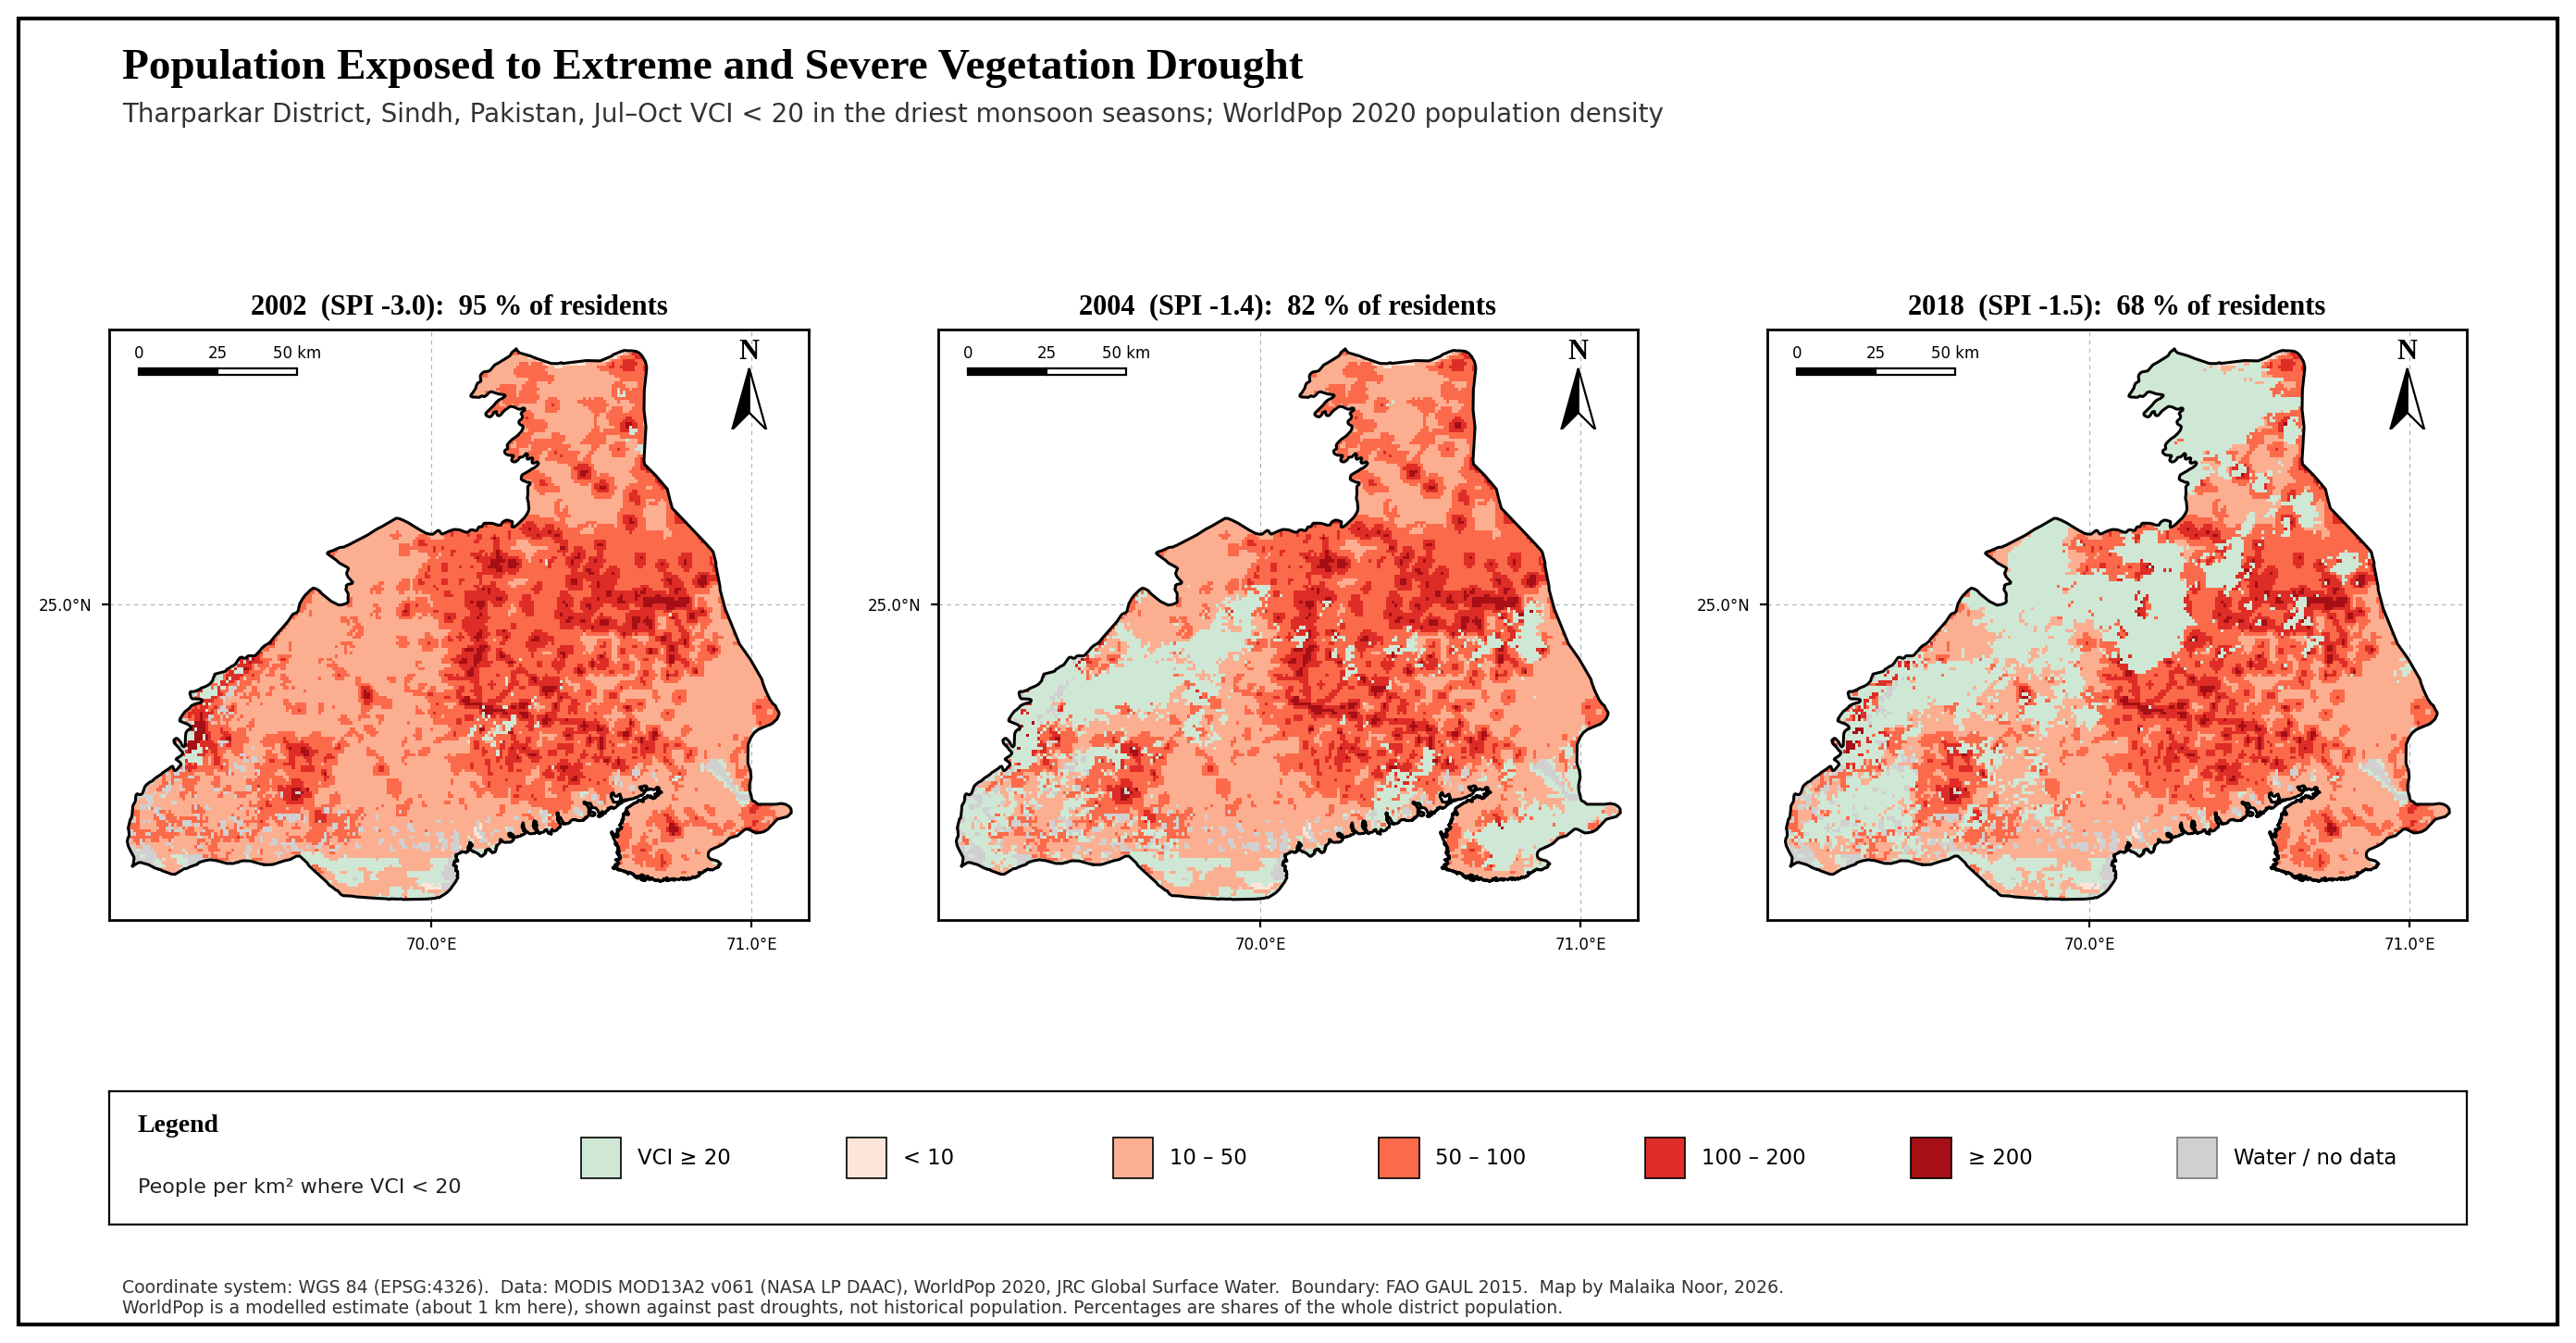

Saved outputs/map_06_population_exposure.png


In [ ]:
# ===== CELL 7: exposure map - population density in extreme/severe vegetation-drought areas =====
# needs Cell 5 (map helpers) and Cell 6 (P, in_district, district_pop, T, BND)
lat_mid = (BND.bottom + BND.top) / 2
pix_km2 = (abs(T.a) * 111.32 * np.cos(np.radians(lat_mid))) * (abs(T.e) * 110.57)
dens = P / pix_km2                                   # people per km2 in each ~1 km pixel
_, bnd0 = read_layer('vci_2002')

items, shares = [], {}
for y in DRY:
    v, _ = read_layer(f'vci_{y}')
    v = clean_layer(v, bnd0, f'vci_{y}')
    valid = np.isfinite(v) & in_district
    exposed = valid & (v < 20)                       # extreme + severe vegetation drought
    shares[y] = 100 * float(P[exposed].sum()) / district_pop
    code = np.full(v.shape, np.nan)
    code[valid] = -1                                 # valid pixel, not in the extreme/severe zone
    code[exposed] = dens[exposed]
    items.append((code, bnd0, f'{y}  (SPI {spi[y]:.1f}):  {shares[y]:.0f} % of residents'))
print('Share of district population living in extreme/severe VCI zones:',
      {y: round(s, 1) for y, s in shares.items()})

panel_map(items, 'outputs/map_06_population_exposure.png',
          'Population Exposed to Extreme and Severe Vegetation Drought',
          SUB + ', Jul–Oct VCI < 20 in the driest monsoon seasons; WorldPop 2020 population density',
          'People per km² where VCI < 20',
          [-2, -0.5, 10, 50, 100, 200, 1e9],
          ['#cfe8d5', '#fee5d9', '#fcae91', '#fb6a4a', '#de2d26', '#a50f15'],
          ['VCI ≥ 20', '< 10', '10 – 50', '50 – 100', '100 – 200', '≥ 200'],
          'MODIS MOD13A2 v061 (NASA LP DAAC), WorldPop 2020, JRC Global Surface Water',
          note='WorldPop is a modelled estimate (about 1 km here), shown against past droughts, not historical population. '
               'Percentages are shares of the whole district population.',
          nodata=True)

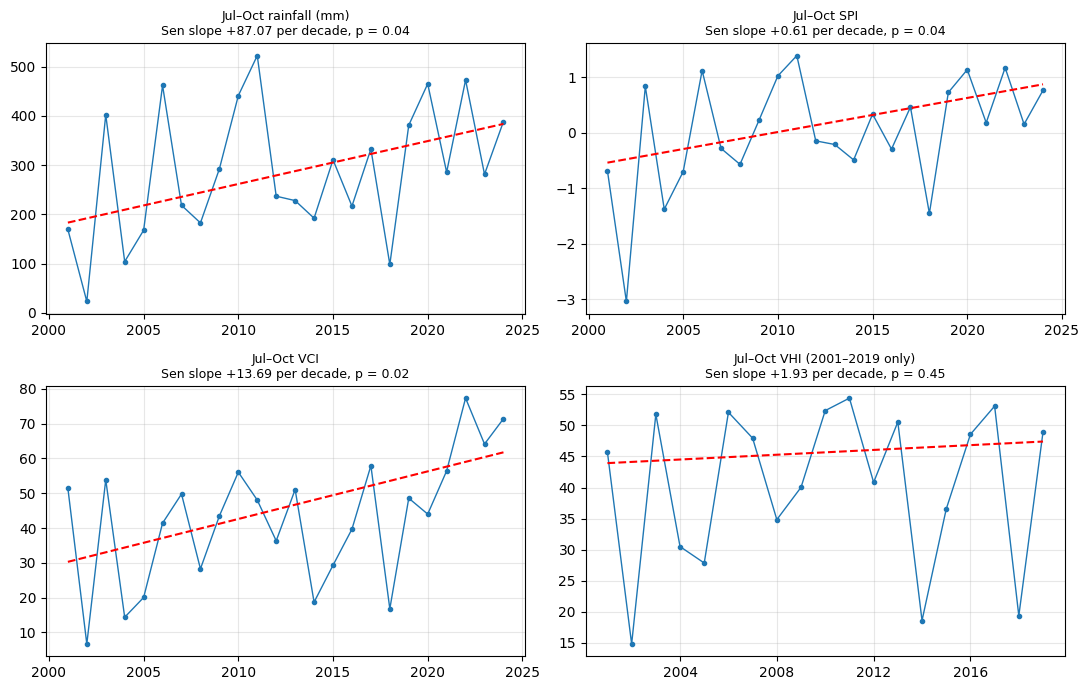

VCI vs rainfall: correlation = 0.69, slope = 9.5 VCI units per 100 mm
                                      Series  n years  Kendall tau  p-value  Sen slope per decade Sen slope 95% CI per decade
                       Jul–Oct rainfall (mm)       24         0.30    0.044                 87.07              2.36 to 155.51
                                 Jul–Oct SPI       24         0.30    0.044                  0.61                0.01 to 1.10
                                 Jul–Oct VCI       24         0.35    0.017                 13.69               2.15 to 26.07
                Jul–Oct VHI (2001–2019 only)       19         0.13    0.447                  1.93              -7.04 to 16.12
         Jul–Oct rainfall (mm), without 2002       23         0.24    0.114                 63.05            -21.34 to 138.75
                   Jul–Oct VCI, without 2002       23         0.30    0.050                 12.34              -0.32 to 22.82
Jul–Oct VCI residual after removing rainfall    

In [ ]:
# ===== CELL 8 (final): trend tests with sensitivity checks =====
from scipy import stats
from matplotlib.ticker import MaxNLocator

def trend_row(label, x, y):
    tau, p = stats.kendalltau(x, y)
    s, i, lo, hi = stats.theilslopes(y, x)
    return ({'Series': label, 'n years': len(x), 'Kendall tau': round(tau, 2), 'p-value': round(p, 3),
             'Sen slope per decade': round(s * 10, 2),
             'Sen slope 95% CI per decade': f'{lo * 10:.2f} to {hi * 10:.2f}'}, s, i, p)

series = [('Jul–Oct rainfall (mm)', 'rain_JulOct', d),
          ('Jul–Oct SPI', 'SPI_JulOct', d),
          ('Jul–Oct VCI', 'VCI_JulOct', d),
          (f'Jul–Oct VHI ({START_YEAR}–{DRIFT_FROM - 1} only)', 'VHI_JulOct', d[d['year'] < DRIFT_FROM])]
rows = []
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (lab, col, df) in zip(axs.ravel(), series):
    x = df['year'].values.astype(float); yv = df[col].values
    row, s, i, p = trend_row(lab, x, yv); rows.append(row)
    ax.plot(x, yv, 'o-', ms=3, lw=1); ax.plot(x, i + s * x, 'r--')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))      # whole years only
    ax.set_title(f'{lab}\nSen slope {s * 10:+.2f} per decade, p = {p:.2f}', fontsize=9); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/fig_trends.png', dpi=200); plt.show()

# sensitivity 1: leave out the 2002 extreme drought (start of the record)
d2 = d[d['year'] != 2002]
for lab, col in [('Jul–Oct rainfall (mm), without 2002', 'rain_JulOct'), ('Jul–Oct VCI, without 2002', 'VCI_JulOct')]:
    rows.append(trend_row(lab, d2['year'].values.astype(float), d2[col].values)[0])

# sensitivity 2: VCI trend after removing the rainfall relationship
b, a0 = np.polyfit(d['rain_JulOct'], d['VCI_JulOct'], 1)
resid = (d['VCI_JulOct'] - (a0 + b * d['rain_JulOct'])).values
rows.append(trend_row('Jul–Oct VCI residual after removing rainfall', d['year'].values.astype(float), resid)[0])
print(f'VCI vs rainfall: correlation = {d["VCI_JulOct"].corr(d["rain_JulOct"]):.2f}, '
      f'slope = {b * 100:.1f} VCI units per 100 mm')

trend = pd.DataFrame(rows)
trend.to_csv('outputs/trend_tests.csv', index=False)
print(trend.to_string(index=False))